# MISTy on lineage markers, metabolic markers and cell types per FOV quadrant (non-TMA dataset)

Same analysis as `MistySampling.ipynb`, but each 2048x2048 pixel FOV of the new dataset is split into 4 quadrants of 1024x1024 pixels, to match the FOV size of the original TMA dataset. MISTy signatures are then obtained per quadrant instead of per FOV.

MISTy is run three times: on lineage markers, on metabolic markers (as in `MistySampling.ipynb`), and on one-hot encoded cell types (as in `notebooks/spatial/MistyLines.ipynb`).

Quadrants with few epithelial cells are excluded, with the same filter as the original MISTy analyses.

This notebook should be run with the root of the repository as working directory.

## Imports

In [24]:
library(mistyR)
library(tidyverse)
library(future)
library(proxy)
library(withr)
library(igraph)
library(ggplot2)
library(DBI)
library(RSQLite)

## Cell table with quadrant metadata

In [25]:
# Load the transformed cell table of the new dataset
cells = read_csv("./data/sampling/cell_table_transformed.csv")
# Consensus cell types transferred from the TMA dataset (see AnnotationTransfer.ipynb)
annotation = read_csv("./data/sampling/annotation_consensus.csv",
                      col_names = c("fov", "label", "annotation_consensus"))
cells <- cells %>% left_join(annotation, by = c("fov", "label"))
stopifnot(!any(is.na(cells$annotation_consensus)))

New names:
• `` -> `...1`
Rows: 683041 Columns: 51
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): fov
dbl (50): ...1, CD4, CD20, FoxP3, CD14, GLUT1, nuclei, COL1A1, CD68, CS, Cyt...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 683041 Columns: 3
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr (2): fov, annotation_consensus
dbl (1): label

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this 

In [26]:
# FOVs are 2048x2048 pixels, split in 4 quadrants of 1024x1024 pixels based on the cell centroids
# centroid-0 is the row (0-indexed, i.e. pixels 1-1024 are below 1024) and centroid-1 the column:
#   A: top-left, B: top-right, C: bottom-left, D: bottom-right
# FOVs are named <patient>_<region>_<replicate>, with region TC (tumor core) or IM (invasive margin)
cells <- cells %>% mutate(
    quadrant = case_when(
        `centroid-0` < 1024 & `centroid-1` < 1024 ~ "A",
        `centroid-0` < 1024 & `centroid-1` >= 1024 ~ "B",
        `centroid-0` >= 1024 & `centroid-1` < 1024 ~ "C",
        `centroid-0` >= 1024 & `centroid-1` >= 1024 ~ "D"),
    patient = str_extract(fov, "^CRC-IFN_ACCC_[0-9]+"),
    region = str_extract(fov, "(?<=_)(TC|IM)(?=_)"),
    fov_quadrant = paste0(fov, "_", quadrant)
)
stopifnot(!any(is.na(cells %>% select(quadrant, patient, region))))

cells %>% count(region, quadrant)
cells %>% count(fov_quadrant) %>% pull(n) %>% summary()

region,quadrant,n
<chr>,<chr>,<int>
IM,A,84244
IM,B,85313
IM,C,83086
IM,D,80249
TC,A,90934
TC,B,90672
TC,C,85379
TC,D,83164


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    5.0   921.5  1099.0  1094.6  1277.0  2106.0 

In [27]:
cells %>% write_csv("./data/sampling/cell_table_transformed_quadrants.csv")

## Quadrant filtering

As in the original MISTy analyses (`MistyLines.ipynb` and `MistyMetab.ipynb`, with the criterion defined in `StageXGB.ipynb`), we exclude quadrants with 20 epithelial cells or fewer: they might only add noise to the analysis, which focuses on the cellular organization around the colorectal epithelium.

In [28]:
epithelial_counts <- cells %>%
    group_by(fov_quadrant, region) %>%
    summarise(n_epithelial = sum(annotation_consensus == "Cancer_cell"), .groups = "drop")
sparse_epi_quadrants <- epithelial_counts %>% filter(n_epithelial <= 20) %>% pull(fov_quadrant)

epithelial_counts %>%
    mutate(excluded = fov_quadrant %in% sparse_epi_quadrants) %>%
    count(region, excluded)

cells <- cells %>% filter(!(fov_quadrant %in% sparse_epi_quadrants))

region,excluded,n
<chr>,<lgl>,<int>
IM,FALSE,223
IM,TRUE,89
TC,FALSE,302
TC,TRUE,10


## Parameters

In [29]:
paraview_l <- 120 # Distance in pixels up to which an effect will be considered in the paraview
juxtaview_l <- 40 # Distance in pixels up to which a cell is considered a direct neighbor
paraview_name <- paste0("paraview.", paraview_l)
juxtaview_name <- paste0("juxtaview.", juxtaview_l)

# Lineage markers of the new panel
lineage_panel = c('PanCK_EpCAM', 'HNF4a', 'SMA', 'Vimentin', 'COL1A1', 'CD31',
                  'CD45', 'CD3e', 'CD4', 'CD8', 'FoxP3', 'CD20', 'CD14',
                  'CD68', 'CD163', 'Calprotectin')
lineage_outputfile = "misty_sampling_quadrant_lineage_multiview.sqm"

# Metabolic markers of the original analysis (except CA9, GS and ARG1, absent from the new panel), and CD36
metab_panel = c('CD98', 'CytC', 'MCT1', 'ASCT2', 'LDH', 'GLS', 'ATP5A', 'CS',
                'PKM2', 'GLUT1', 'CPT1A', 'Ki67', 'CD36')
metab_outputfile = "misty_sampling_quadrant_metabolism_multiview.sqm"

celltype_outputfile = "misty_sampling_quadrant_celltype_multiview.sqm"

fig_dir <- "figures/sampling/misty_quadrants"
dir.create(fig_dir, recursive = TRUE, showWarnings = FALSE)

# All markers and coordinates should be in the cell table
stopifnot(all(c(lineage_panel, metab_panel, "centroid-0", "centroid-1") %in% colnames(cells)))

## One-hot encoded cell types

As in `MistyLines.ipynb`, cells with an "Unclear" label are dropped for the cell type run only. Note that we use a fixed radius in the MISTy views, so removing these cells should not affect the interactions between annotated cells.

In [30]:
cells_celltype <- cells %>% filter(annotation_consensus != "Unclear")
celltype_panel <- sort(unique(cells_celltype$annotation_consensus))

# One column per cell type, with 1 if the cell has this type and 0 otherwise
for (cell_type in celltype_panel) {
    cells_celltype[[cell_type]] <- as.integer(cells_celltype$annotation_consensus == cell_type)
}
celltype_panel

[1] "B_cell"            "CAF"               "Cancer_cell"      
 [4] "CD163_Macrophage"  "CD4_Tcell"         "CD68_Macrophage"  
 [7] "CD8_Tcell"         "Endothelial_cell"  "Monocyte"         
[10] "Neutrophil"        "NK_cell"           "Other_immune_cell"
[13] "T_reg_cell"

## Run MISTy

In [31]:
# Targets MISTy keeps for a quadrant (same filtering as in run_misty)
expected_targets <- function(markers_quadrant, cv.strict, cv.folds = 10) {
    markers_quadrant %>%
        select(where(~ sd(.) > 0 & length(unique(.)) >= ifelse(cv.strict, cv.folds, 1))) %>%
        colnames()
}

run_misty_quadrants <- function(cells, panel, outputfile, bypass.intra, cv.strict) {
    # Expected data is a list of tibbles with each one containing the marker expressions (columns) per cell (rows) for a quadrant
    markers <- cells %>% group_by(fov_quadrant) %>% select(all_of(panel)) %>% group_split(.keep = FALSE)
    # Coordinates of each cell
    positions <- cells %>% group_by(fov_quadrant) %>% select(c("centroid-0", "centroid-1")) %>% group_split(.keep = FALSE)
    # Extract the names of the quadrants in the same order as the markers and positions tables
    quadrant_names <- cells %>% group_by(fov_quadrant) %>% summarise(fov_quadrant = first(fov_quadrant)) %>% pull(fov_quadrant)

    # run_misty appends to existing databases, so to resume an interrupted run we skip quadrants with
    # results for all targets, and remove partial results (e.g. if the kernel died while writing)
    done <- c()
    if (file.exists(outputfile)) {
        dbcon <- dbConnect(RSQLite::SQLite(), outputfile)
        # Improvements are written last for each target
        written <- dbGetQuery(dbcon, "SELECT DISTINCT sample, target FROM improvements")
        done <- quadrant_names[map_lgl(seq_along(quadrant_names), function(i) {
            setequal(written$target[written$sample == quadrant_names[i]],
                     expected_targets(markers[[i]], cv.strict))
        })]
        partial <- setdiff(unique(c(
            dbGetQuery(dbcon, "SELECT DISTINCT sample FROM improvements")$sample,
            dbGetQuery(dbcon, "SELECT DISTINCT sample FROM contributions")$sample,
            dbGetQuery(dbcon, "SELECT DISTINCT sample FROM importances")$sample)), done)
        if (length(partial) > 0) {
            message("Removing partial results for: ", paste(partial, collapse = ", "))
            for (table in c("improvements", "contributions", "importances")) {
                dbExecute(dbcon, paste0("DELETE FROM ", table, " WHERE sample = ?"), params = list(partial))
            }
        }
        dbDisconnect(dbcon)
        message(length(done), "/", length(quadrant_names), " quadrants already done.")
    }

    seq_along(markers) %>%
        keep(~ !(quadrant_names[.x] %in% done)) %>%
        walk(
        function(i) {
        misty.views <- create_initial_view(markers[[i]]) %>%
            add_paraview(positions[[i]], paraview_l,
                family = "gaussian", cached = TRUE,
                prefix = "p.", zoi = juxtaview_l,
            ) %>%
            add_juxtaview(positions[[i]], juxtaview_l,
                prefix = "l."
            )

        folders <- run_misty(misty.views,
            sample.id = quadrant_names[i],
            results.db = outputfile,
            bypass.intra = bypass.intra,
            cv.strict = cv.strict,
            sqlite_timeout = 10000
        )})
}

In [32]:
# Lineage markers: intraview skipped, as for cell types in MistyLines.ipynb
run_misty_quadrants(cells, lineage_panel, lineage_outputfile, bypass.intra = TRUE, cv.strict = FALSE)

Adding missing grouping variables: `fov_quadrant`


Adding missing grouping variables: `fov_quadrant`
525/525 quadrants already done.



In [33]:
# Metabolic markers: same settings as MistyMetab.ipynb
run_misty_quadrants(cells, metab_panel, metab_outputfile, bypass.intra = FALSE, cv.strict = TRUE)

Adding missing grouping variables: `fov_quadrant`
Adding missing grouping variables: `fov_quadrant`
525/525 quadrants already done.



In [34]:
# Cell types: same settings as MistyLines.ipynb
# cv.strict should stay FALSE: one-hot columns only have 2 unique values, fewer than the 10 CV folds
run_misty_quadrants(cells_celltype, celltype_panel, celltype_outputfile, bypass.intra = TRUE, cv.strict = FALSE)

Adding missing grouping variables: `fov_quadrant`
Adding missing grouping variables: `fov_quadrant`
525/525 quadrants already done.



## Result summaries

In [35]:
summarise_misty <- function(results, prefix) {
    plot_view_contributions(results)
    ggsave(filename = file.path(fig_dir, paste0(prefix, "_contrib.pdf")), width = 4, height = 4)

    plot_improvement_stats(results)
    ggsave(filename = file.path(fig_dir, paste0(prefix, "_improvements.pdf")), width = 4, height = 4)

    # Mean gain.R2 across quadrants per target
    results$improvements %>%
        filter(measure == "gain.R2") %>%
        group_by(target) %>%
        summarise(mean_value = mean(value, na.rm = TRUE)) %>%
        arrange(desc(mean_value)) %>%
        print()

    for (view in c(paraview_name, juxtaview_name)) {
        view_short <- ifelse(view == paraview_name, "para", "juxta")
        plot_interaction_communities(results, view = view)
        pdf(file.path(fig_dir, paste0(prefix, "_", view_short, "_net.pdf")))
        plot_interaction_communities(results,
            view = view,
            path = file.path(fig_dir, paste0(prefix, "_", view_short, "_net.graphml")))
        dev.off()

        plot_interaction_heatmap(results, view, clean = TRUE, correlation = TRUE)
        ggsave(filename = file.path(fig_dir, paste0(prefix, "_", view_short, "_heatmap.pdf")),
            dpi = 300, height = 3, width = 4)
    }
}

### Lineage markers








Aggregating



# A tibble: 16 × 2
   target       mean_value
   <chr>             <dbl>
 1 PanCK_EpCAM        66.6
 2 COL1A1             53.3
 3 Vimentin           44.1
 4 SMA                43.3
 5 CD45               42.9
 6 CD14               38.6
 7 HNF4a              36.4
 8 CD4                35.2
 9 CD31               33.0
10 Calprotectin       26.3
11 CD3e               25.6
12 CD163              25.1
13 CD68               24.7
14 CD20               24.7
15 FoxP3              22.7
16 CD8                14.1


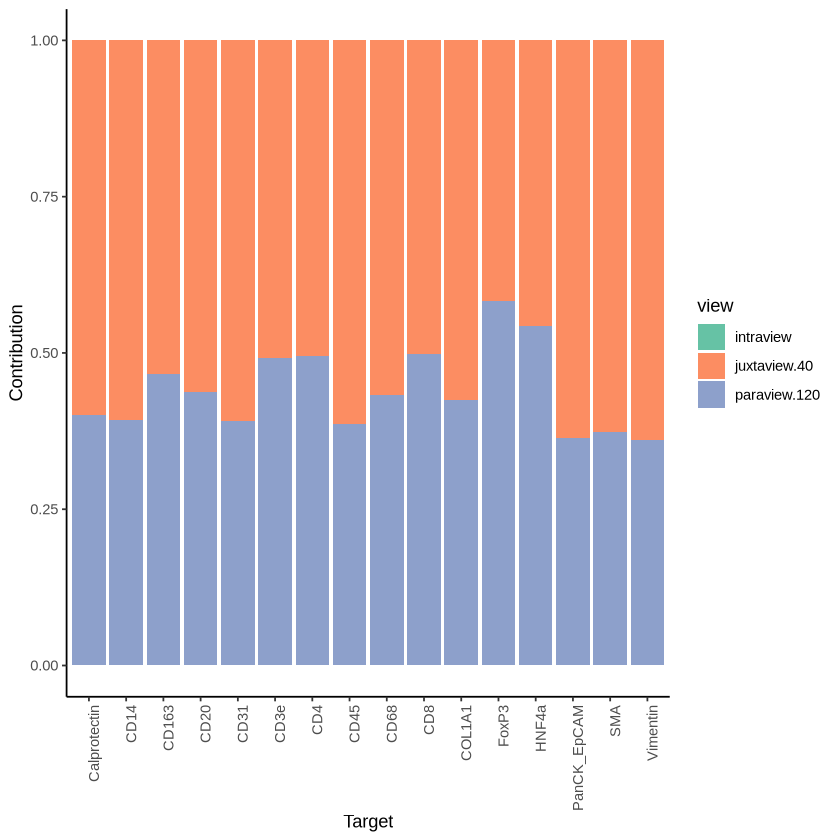

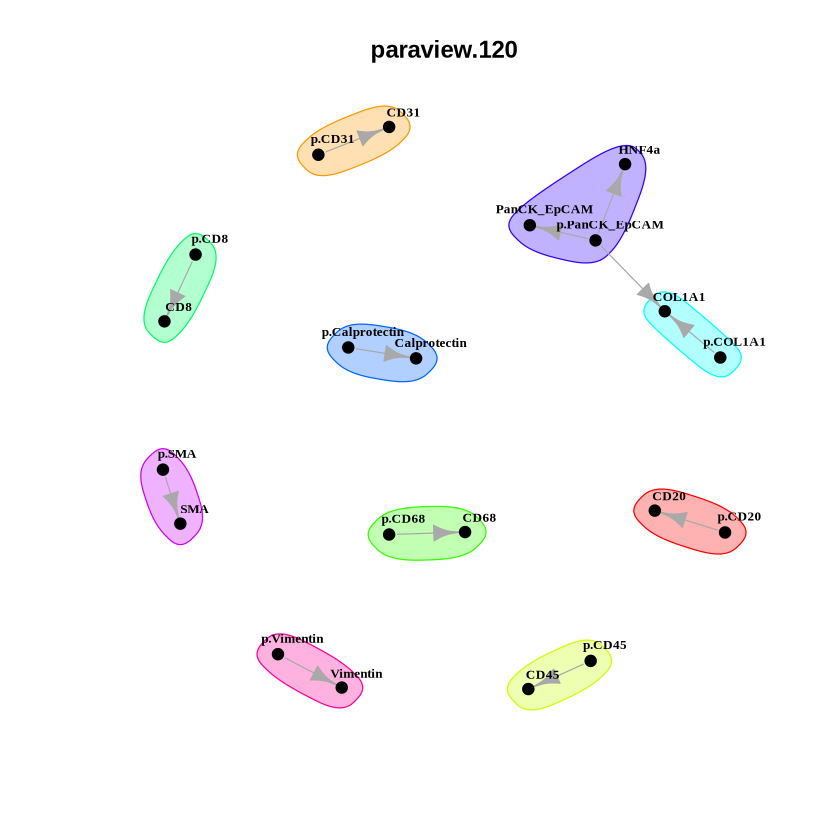

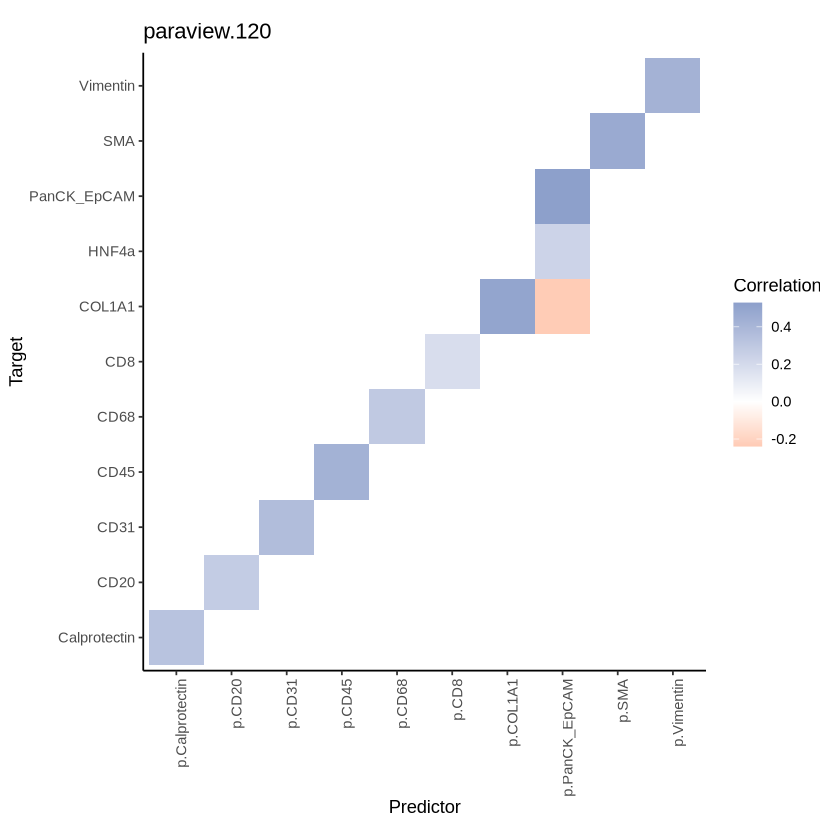

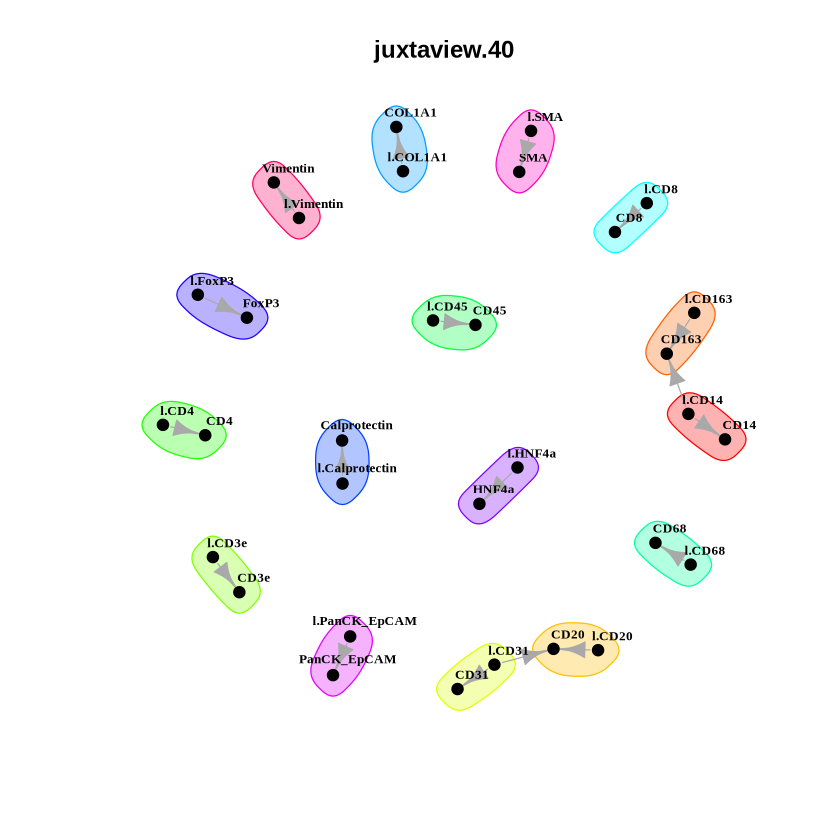

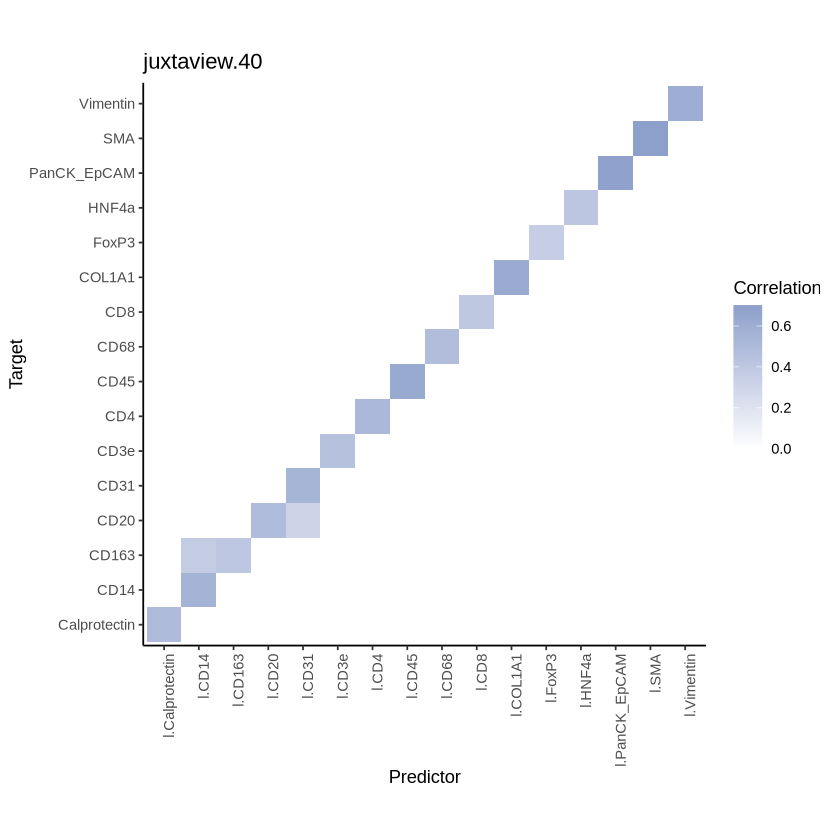

In [36]:
lineage_results <- collect_results(lineage_outputfile)
summarise_misty(lineage_results, "misty_quadrant_lineage_all")

#### Tumor core (TC)








Aggregating



# A tibble: 16 × 2
   target       mean_value
   <chr>             <dbl>
 1 PanCK_EpCAM        64.6
 2 COL1A1             55.1
 3 SMA                46.9
 4 Vimentin           46.4
 5 CD45               41.8
 6 CD14               38.8
 7 HNF4a              36.4
 8 CD4                34.9
 9 CD31               32.6
10 CD3e               24.8
11 CD163              24.7
12 CD20               24.2
13 CD68               24.0
14 Calprotectin       23.4
15 FoxP3              22.5
16 CD8                13.4


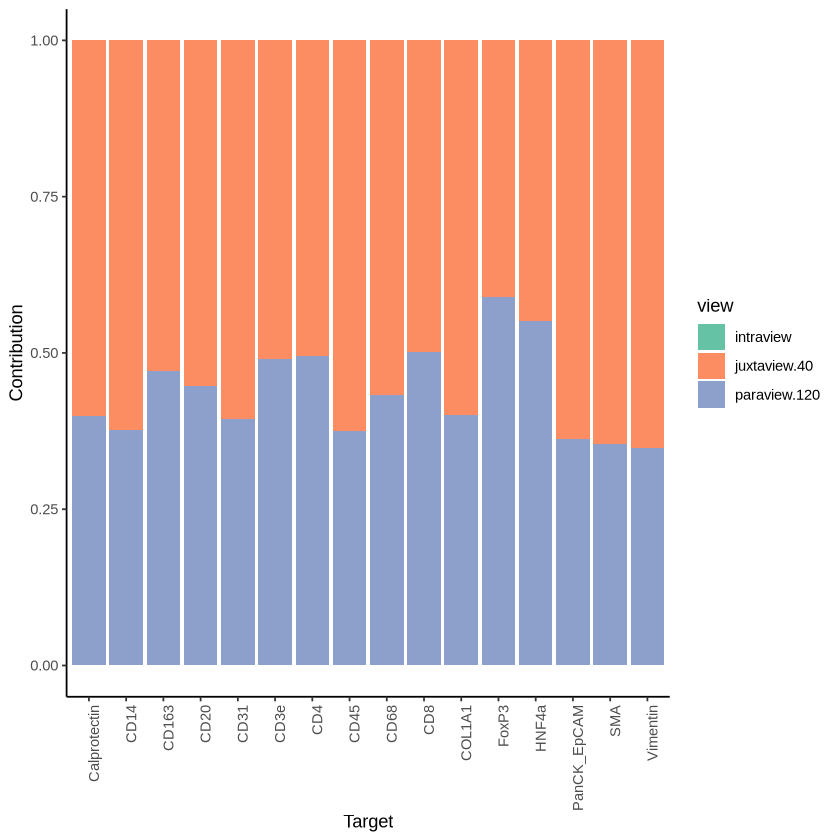

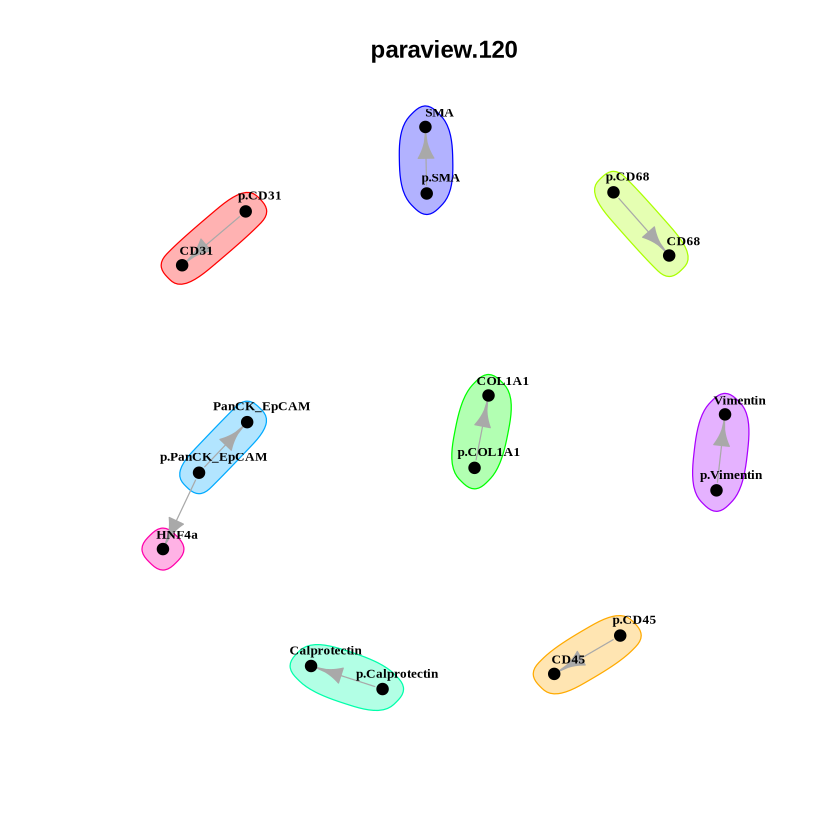

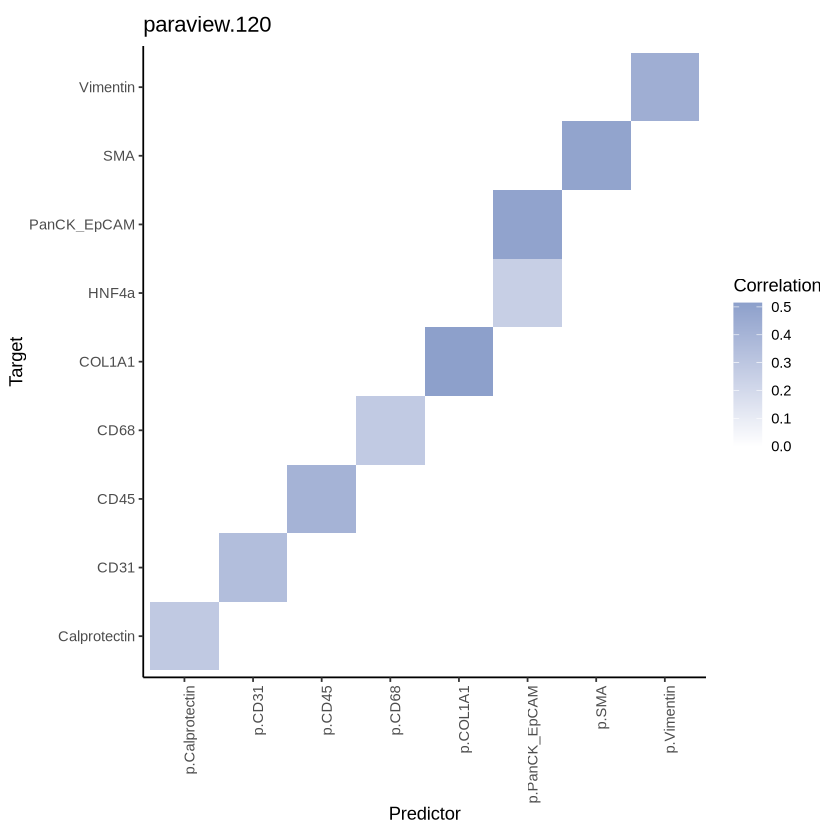

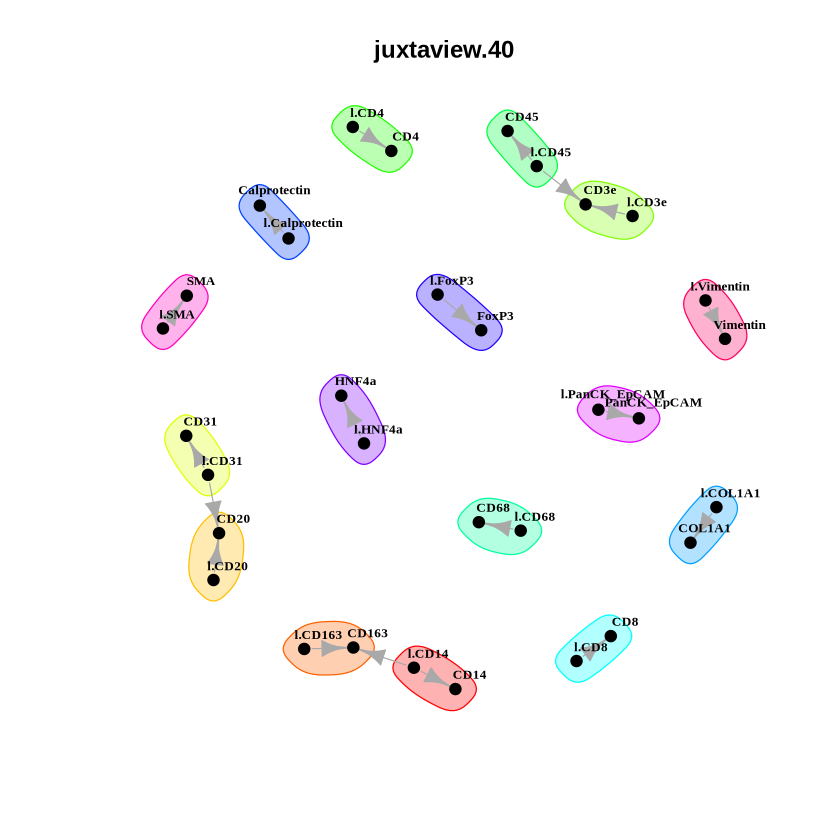

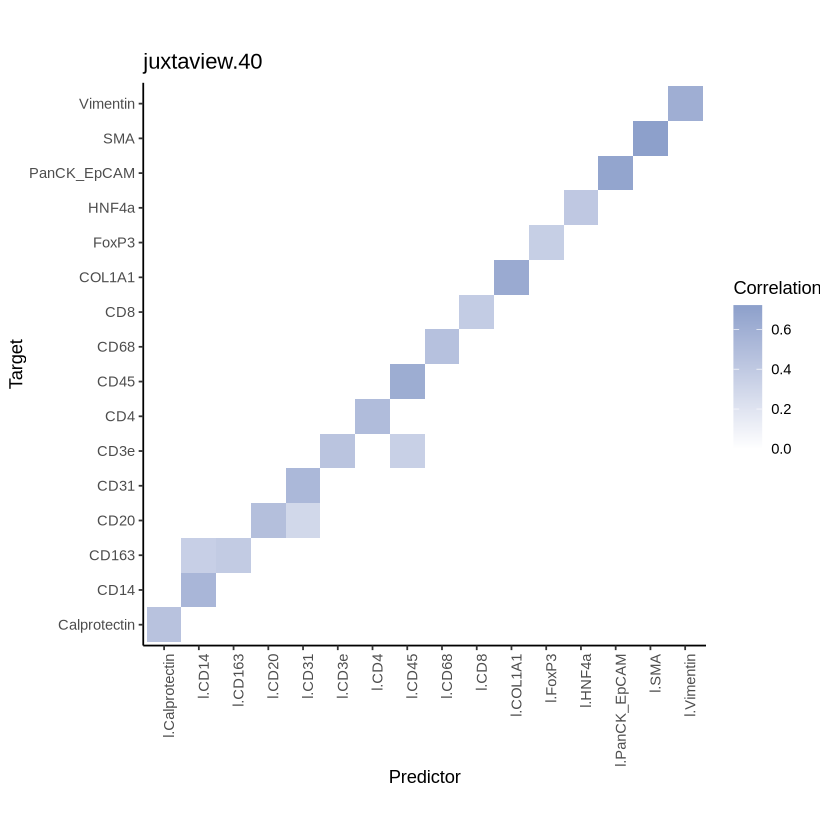

In [37]:
lineage_tc_results <- collect_results(lineage_outputfile, sample.pattern = "_TC_")
summarise_misty(lineage_tc_results, "misty_quadrant_lineage_TC")

#### Invasive margin (IM)








Aggregating



# A tibble: 16 × 2
   target       mean_value
   <chr>             <dbl>
 1 PanCK_EpCAM        69.4
 2 COL1A1             50.9
 3 CD45               44.3
 4 Vimentin           41.1
 5 SMA                38.4
 6 CD14               38.3
 7 HNF4a              36.5
 8 CD4                35.6
 9 CD31               33.6
10 Calprotectin       30.1
11 CD3e               26.6
12 CD68               25.8
13 CD163              25.8
14 CD20               25.2
15 FoxP3              22.9
16 CD8                15.2


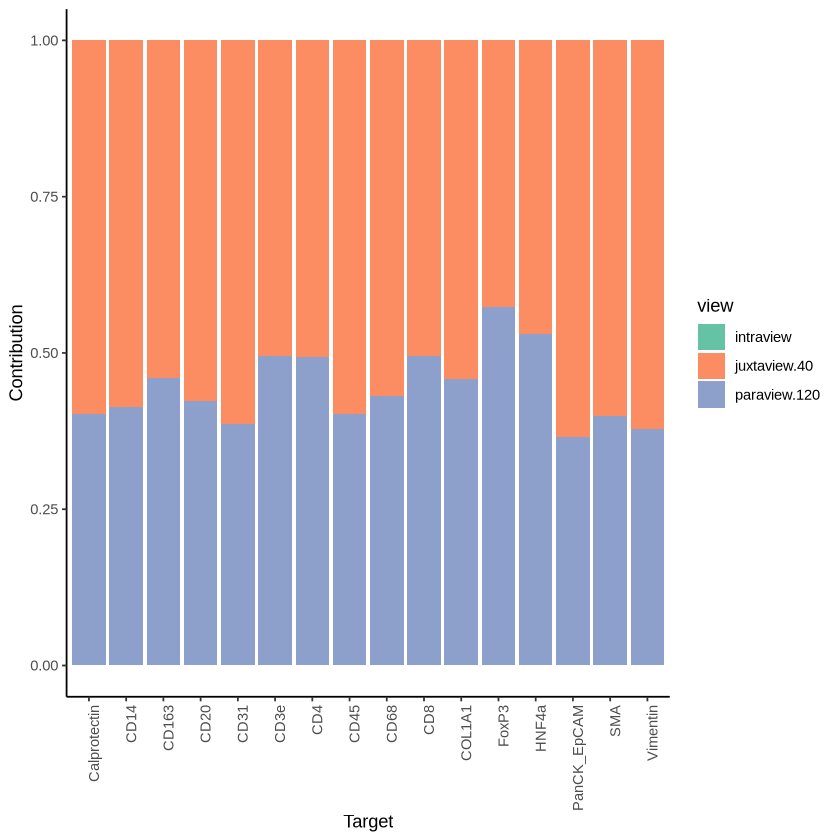

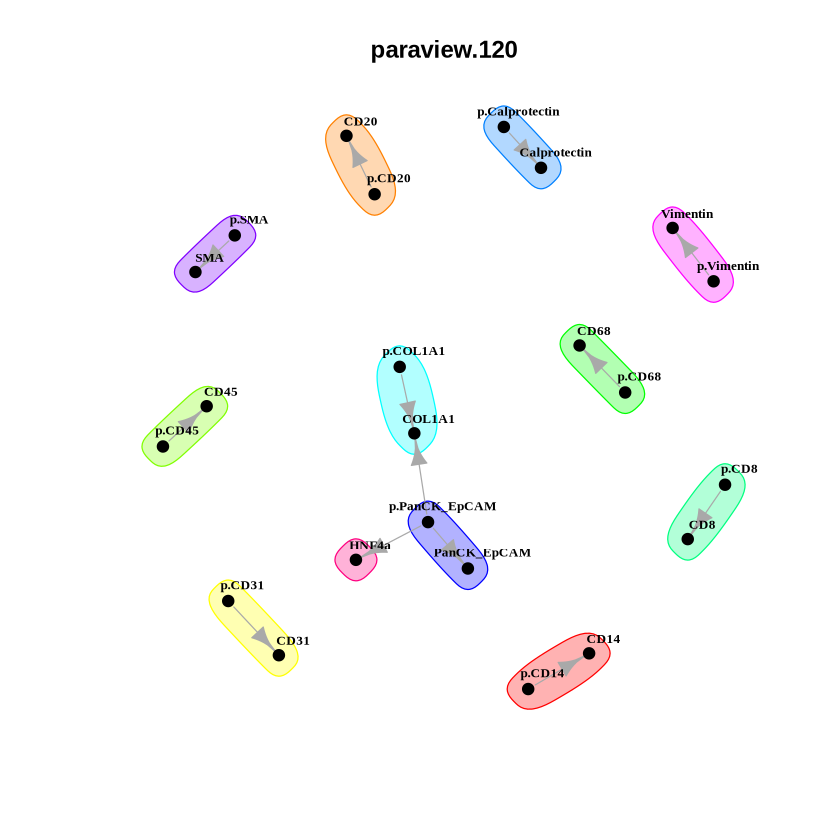

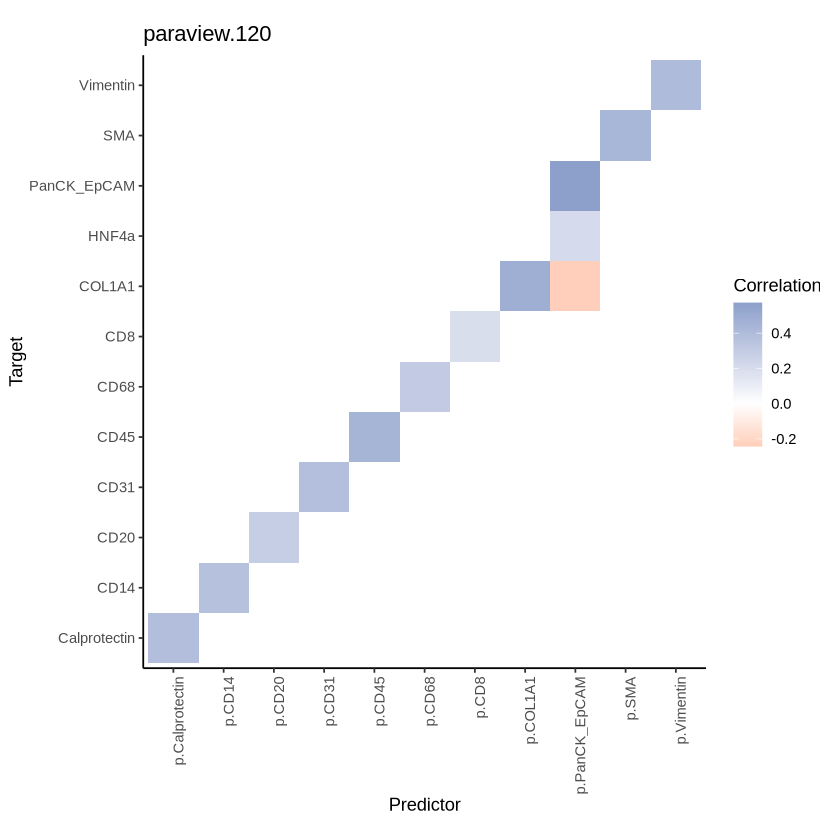

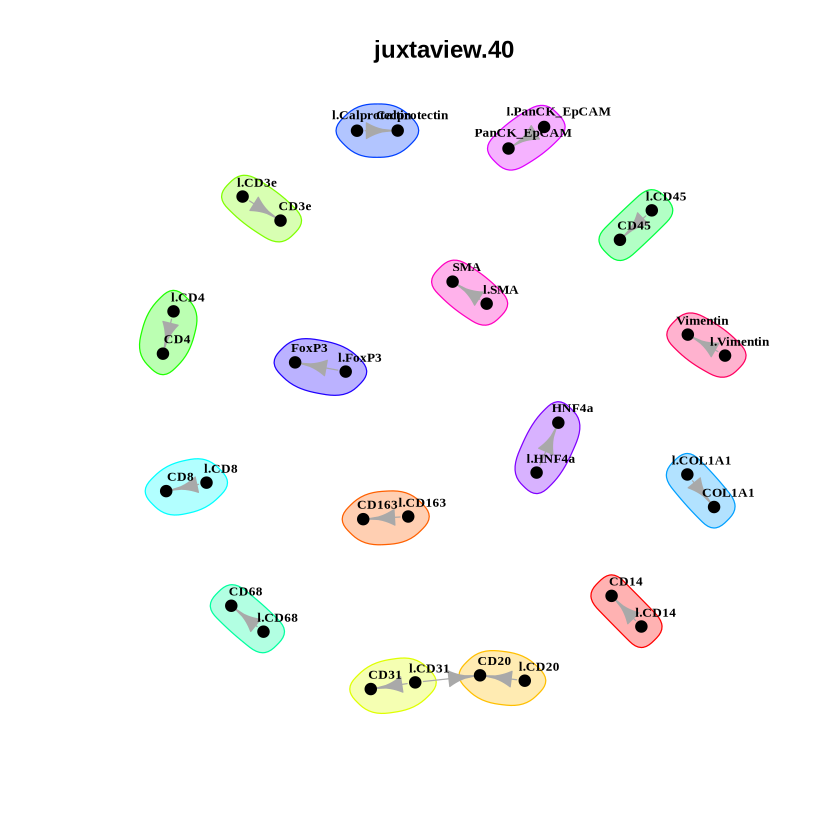

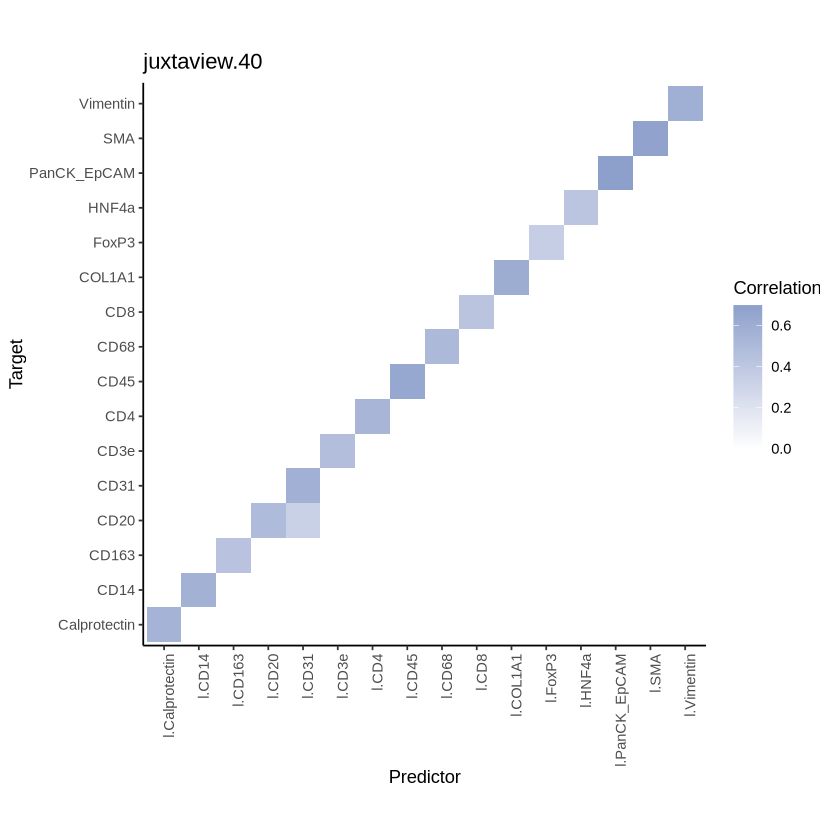

In [38]:
lineage_im_results <- collect_results(lineage_outputfile, sample.pattern = "_IM_")
summarise_misty(lineage_im_results, "misty_quadrant_lineage_IM")

### Metabolic markers








Aggregating



# A tibble: 13 × 2
   target mean_value
   <chr>       <dbl>
 1 Ki67       4.48  
 2 LDH        4.25  
 3 CD36       3.72  
 4 MCT1       2.81  
 5 PKM2       2.57  
 6 CPT1A      2.46  
 7 GLUT1      2.42  
 8 CytC       1.23  
 9 ASCT2      1.18  
10 CD98       1.14  
11 GLS        0.520 
12 CS         0.195 
13 ATP5A      0.0916


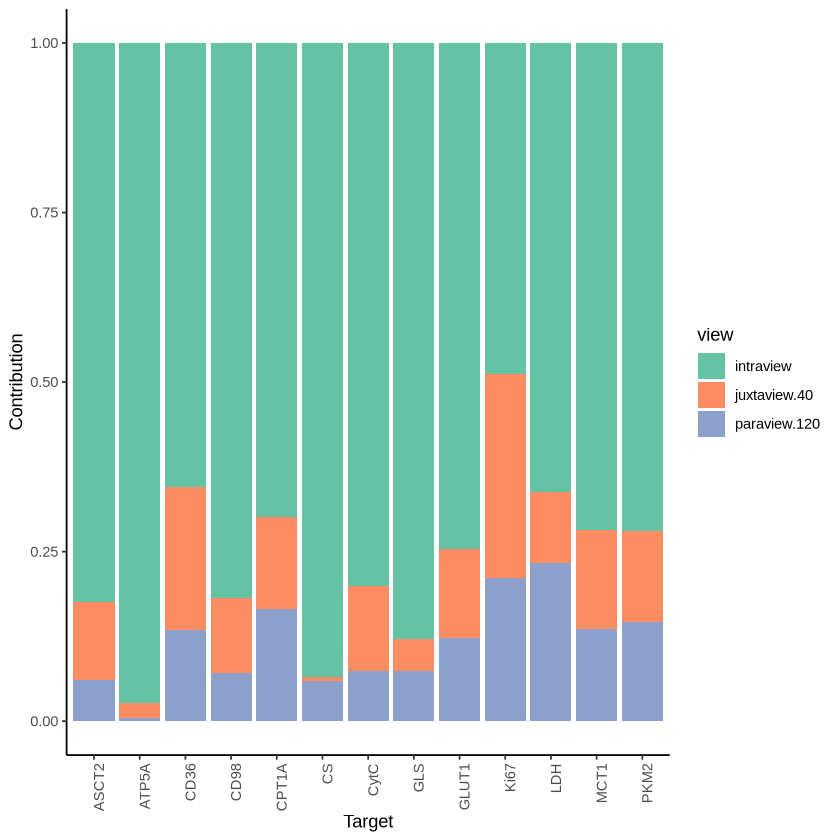

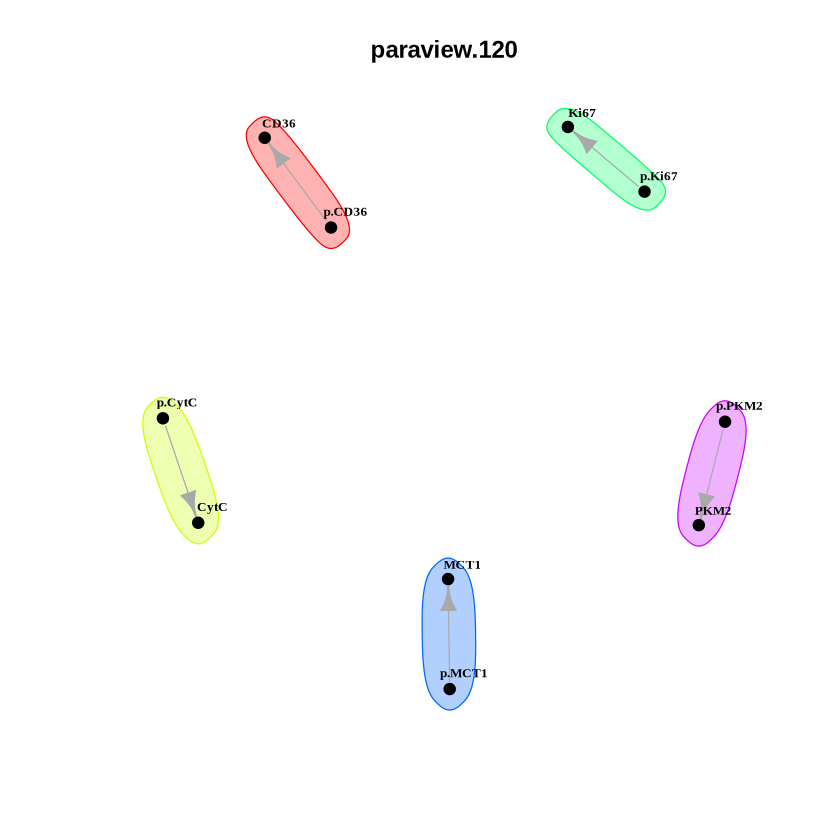

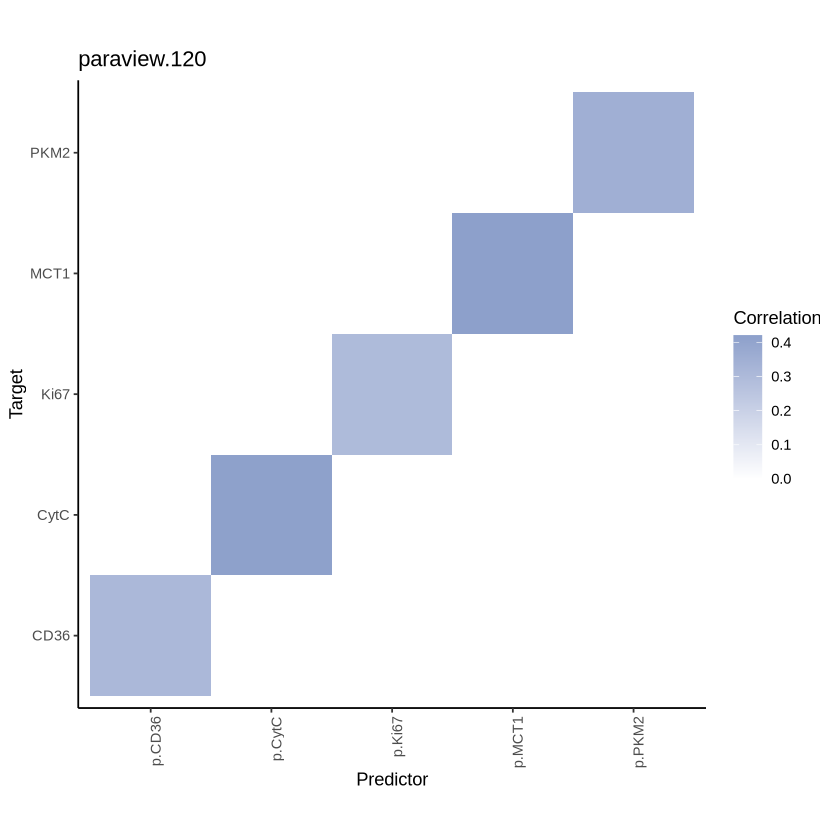

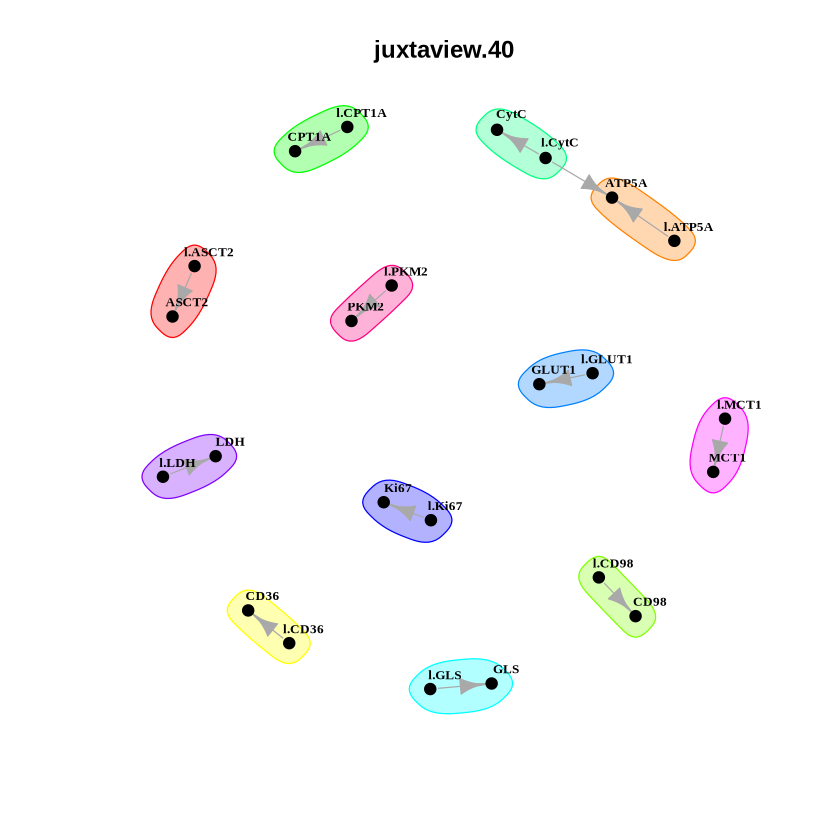

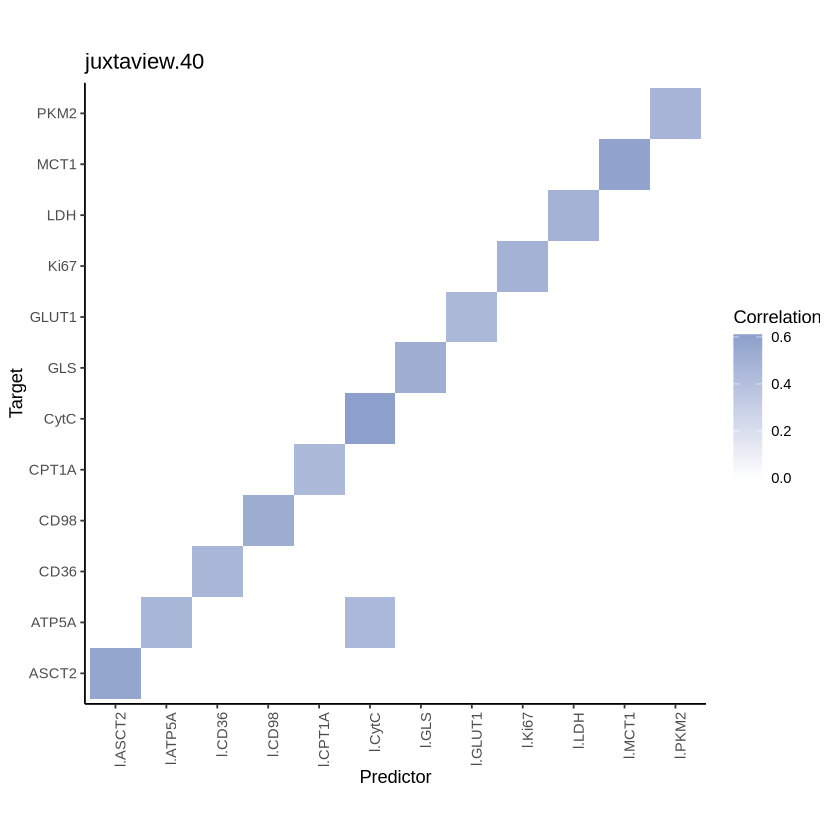

In [39]:
metab_results <- collect_results(metab_outputfile)
summarise_misty(metab_results, "misty_quadrant_metab_all")

#### Tumor core (TC)








Aggregating



# A tibble: 13 × 2
   target mean_value
   <chr>       <dbl>
 1 Ki67       5.01  
 2 LDH        4.81  
 3 CD36       3.50  
 4 MCT1       3.00  
 5 CPT1A      2.77  
 6 PKM2       2.64  
 7 GLUT1      2.47  
 8 ASCT2      1.26  
 9 CD98       1.17  
10 CytC       1.13  
11 GLS        0.616 
12 CS         0.130 
13 ATP5A      0.0703


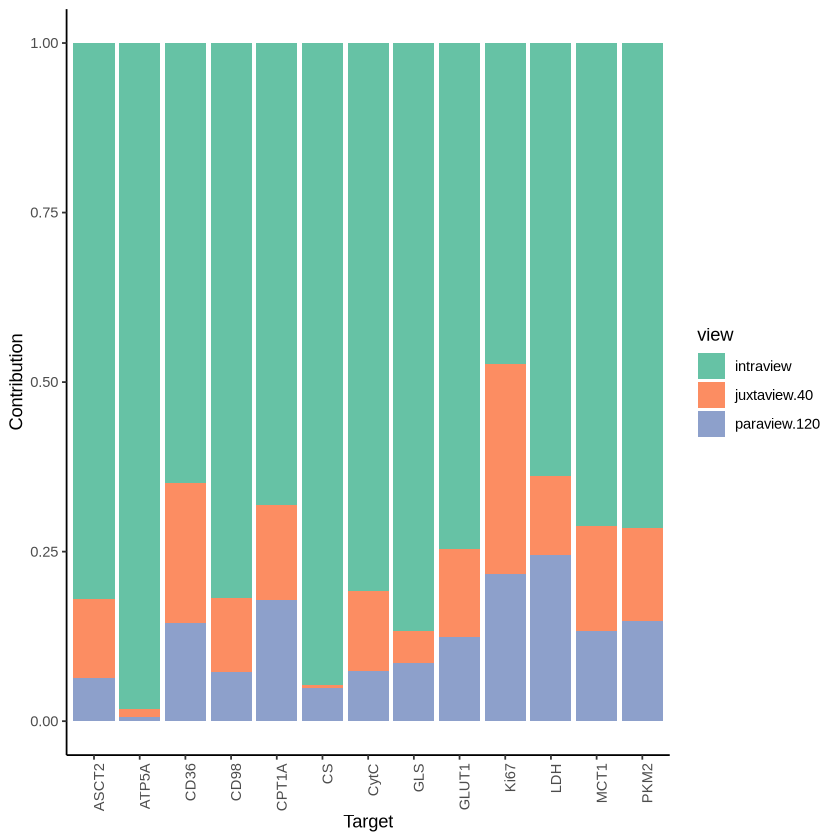

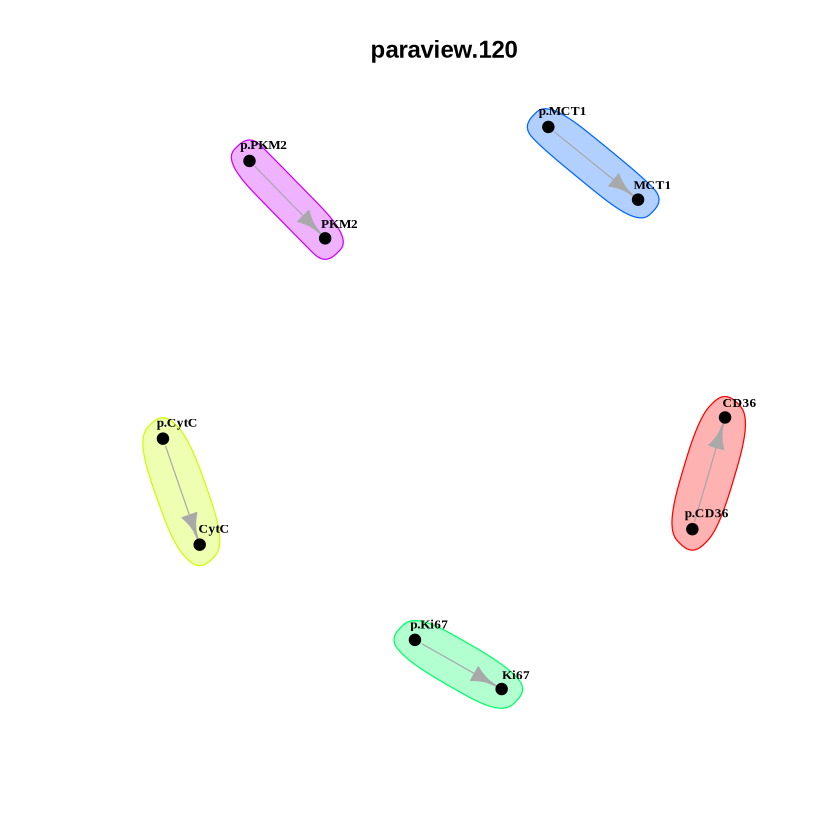

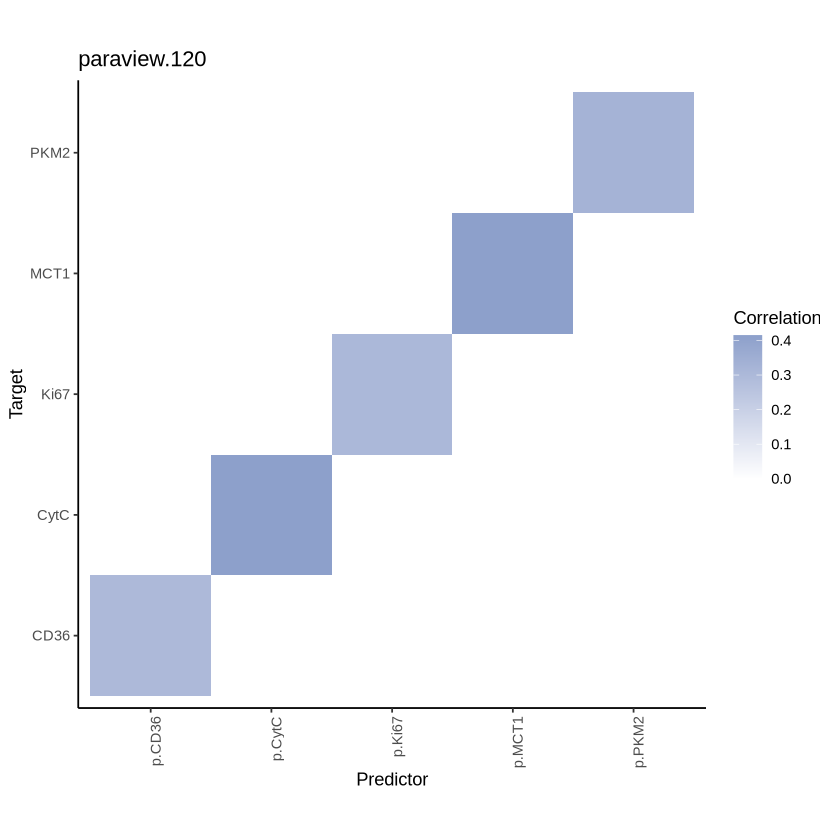

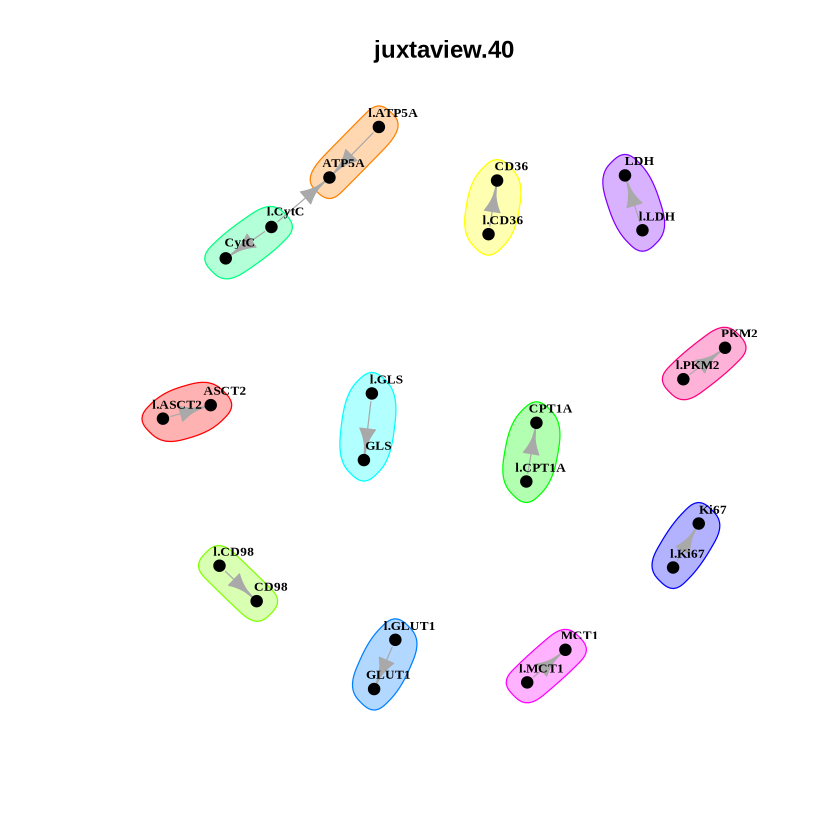

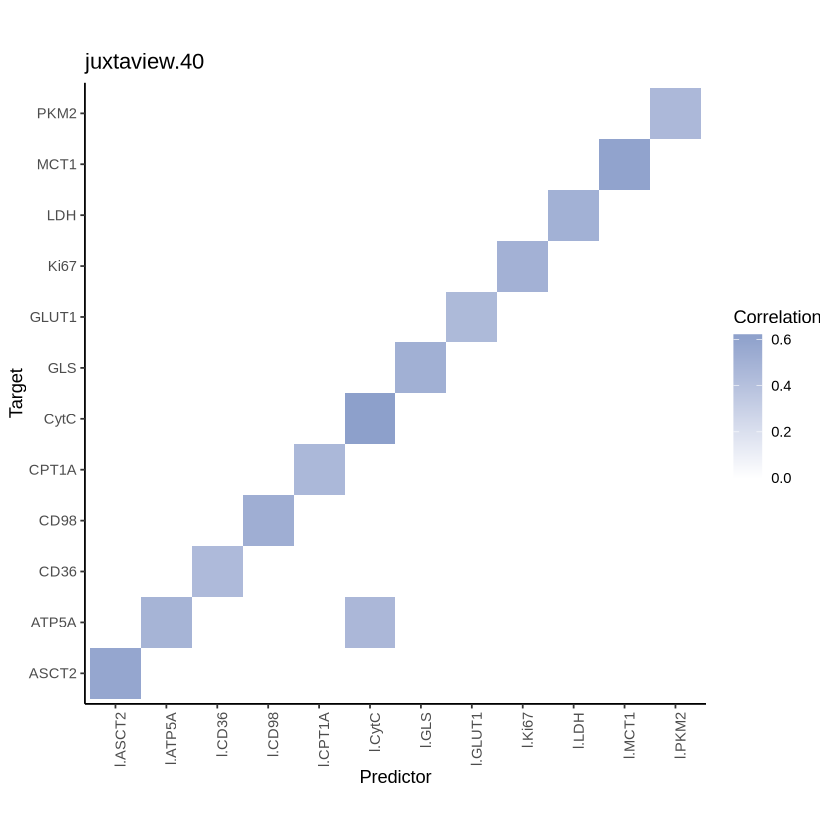

In [40]:
metab_tc_results <- collect_results(metab_outputfile, sample.pattern = "_TC_")
summarise_misty(metab_tc_results, "misty_quadrant_metab_TC")

#### Invasive margin (IM)








Aggregating



# A tibble: 13 × 2
   target mean_value
   <chr>       <dbl>
 1 CD36        4.02 
 2 Ki67        3.77 
 3 LDH         3.51 
 4 MCT1        2.55 
 5 PKM2        2.47 
 6 GLUT1       2.36 
 7 CPT1A       2.04 
 8 CytC        1.36 
 9 CD98        1.09 
10 ASCT2       1.07 
11 GLS         0.391
12 CS          0.284
13 ATP5A       0.121


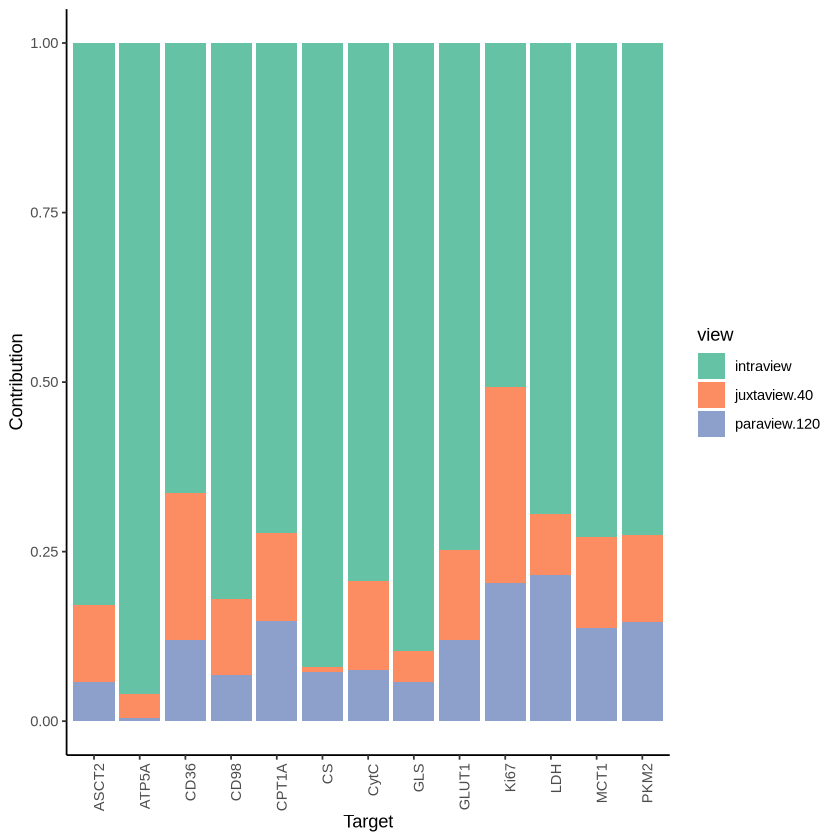

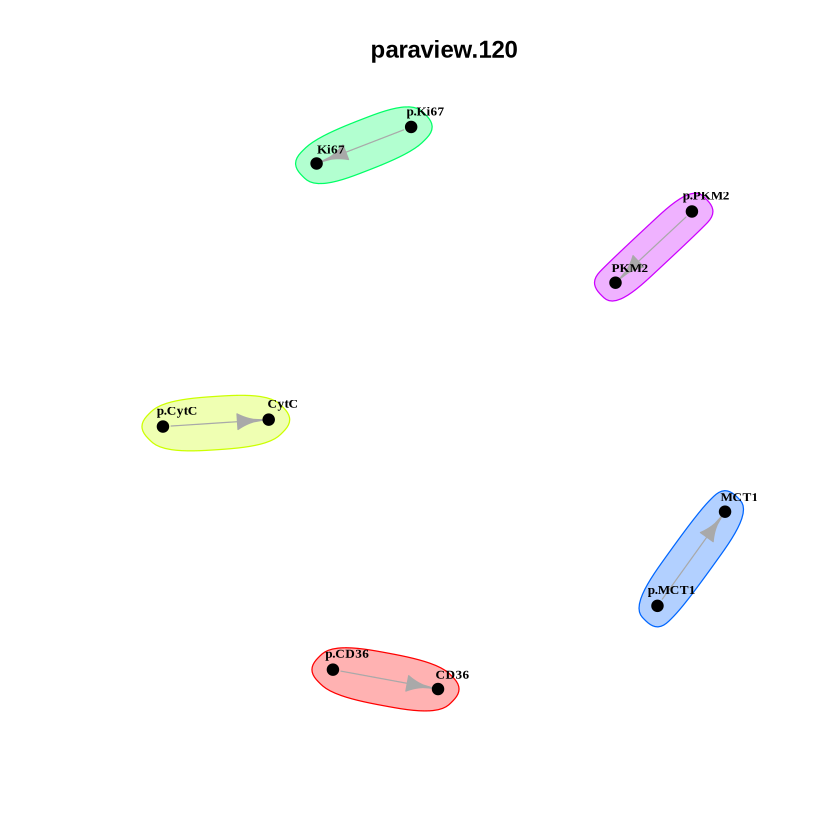

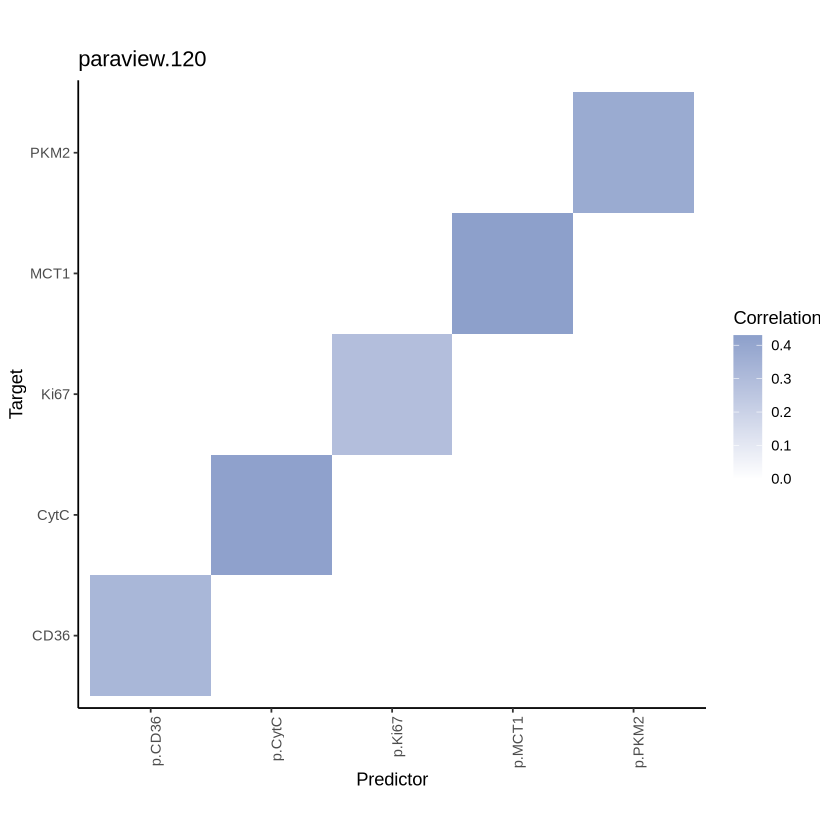

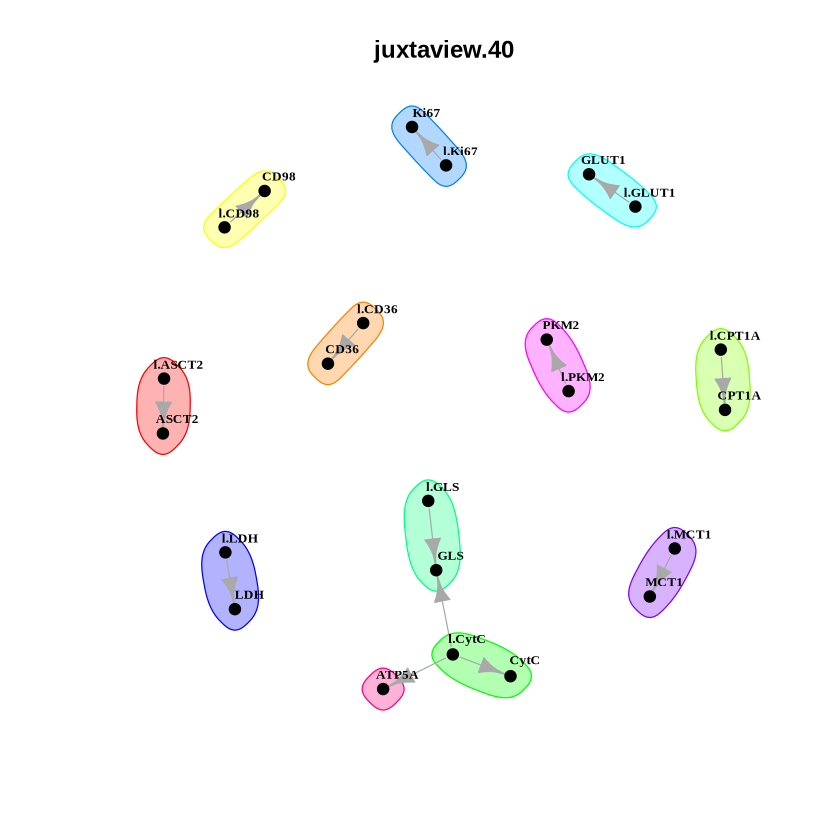

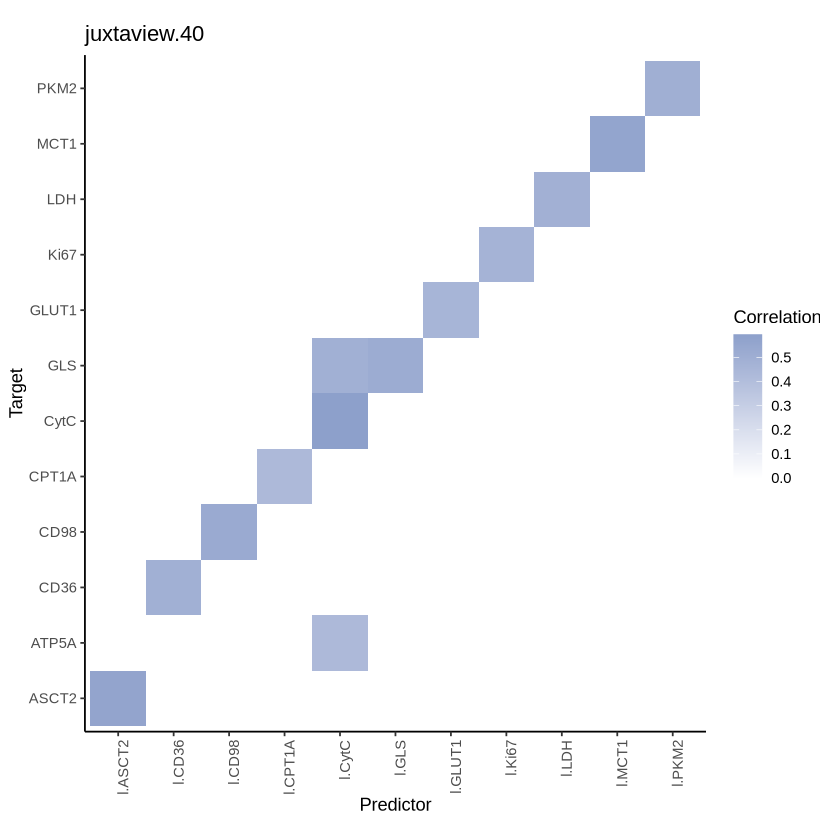

In [41]:
metab_im_results <- collect_results(metab_outputfile, sample.pattern = "_IM_")
summarise_misty(metab_im_results, "misty_quadrant_metab_IM")

### Cell types








Aggregating



# A tibble: 13 × 2
   target            mean_value
   <chr>                  <dbl>
 1 Cancer_cell           69.9  
 2 CAF                   25.3  
 3 Endothelial_cell      23.3  
 4 Neutrophil            17.5  
 5 Monocyte               8.93 
 6 CD4_Tcell              7.91 
 7 CD163_Macrophage       6.34 
 8 CD68_Macrophage        5.69 
 9 Other_immune_cell      5.03 
10 CD8_Tcell              5.03 
11 B_cell                 4.34 
12 T_reg_cell             1.09 
13 NK_cell                0.604


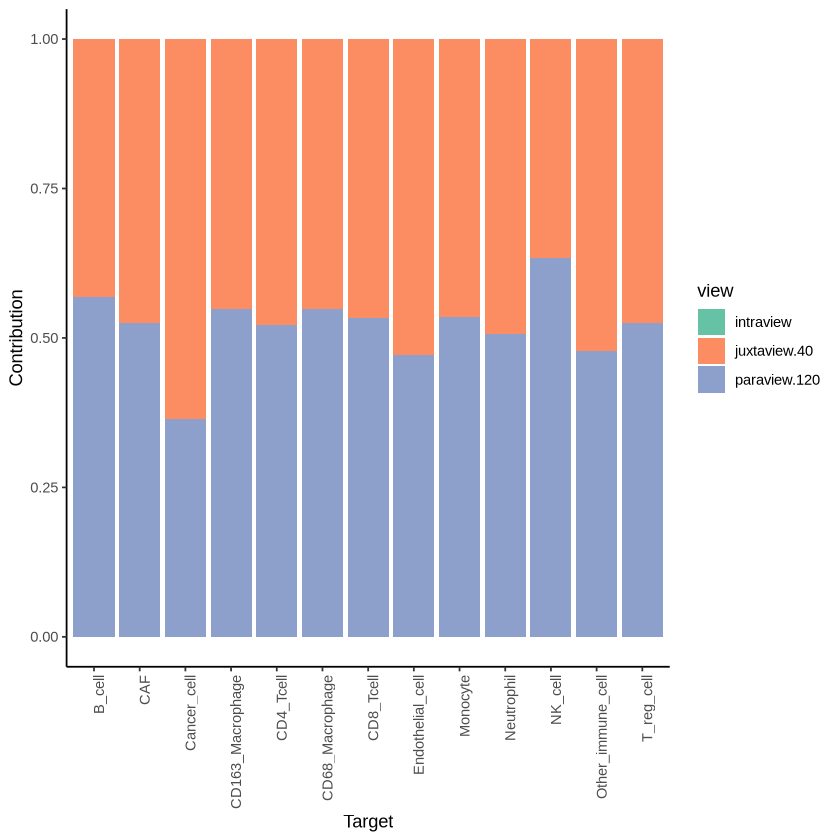

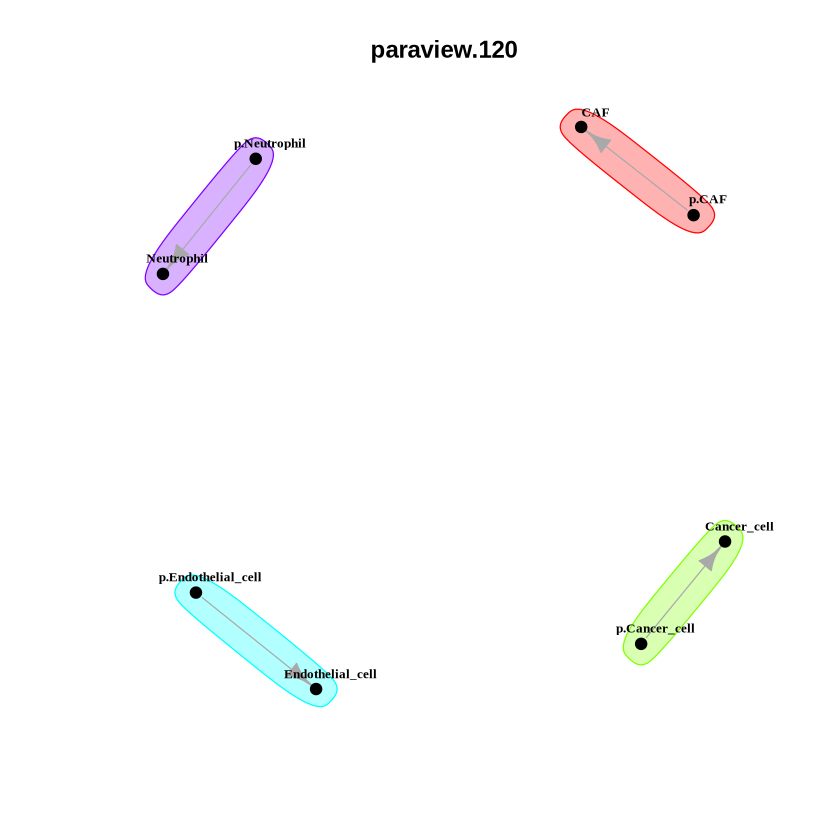

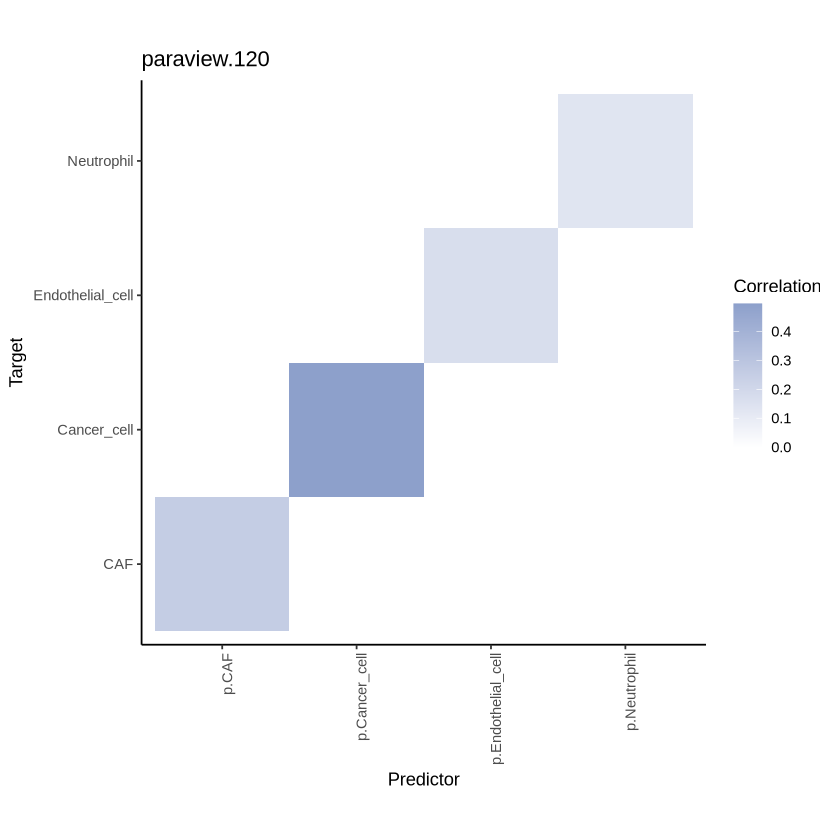

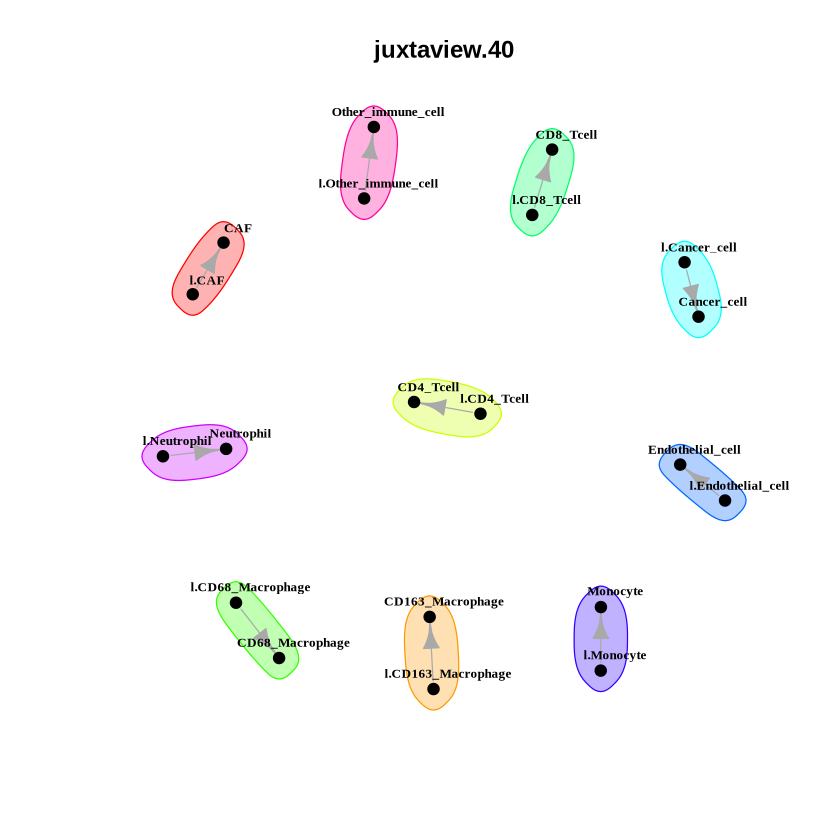

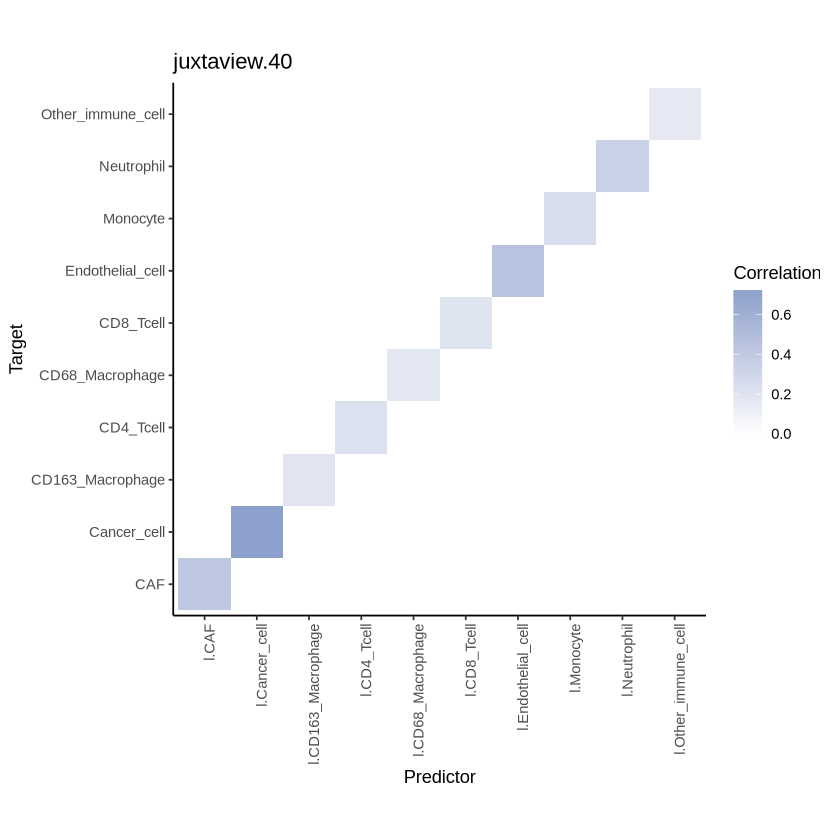

In [42]:
celltype_results <- collect_results(celltype_outputfile)
summarise_misty(celltype_results, "misty_quadrant_celltype_all")

#### Tumor core (TC)








Aggregating



# A tibble: 13 × 2
   target            mean_value
   <chr>                  <dbl>
 1 Cancer_cell           70.6  
 2 CAF                   28.4  
 3 Endothelial_cell      22.4  
 4 Neutrophil            15.2  
 5 Monocyte               8.15 
 6 CD4_Tcell              7.58 
 7 CD163_Macrophage       5.63 
 8 CD68_Macrophage        5.13 
 9 Other_immune_cell      5.12 
10 CD8_Tcell              5.08 
11 B_cell                 4.37 
12 T_reg_cell             1.07 
13 NK_cell                0.521


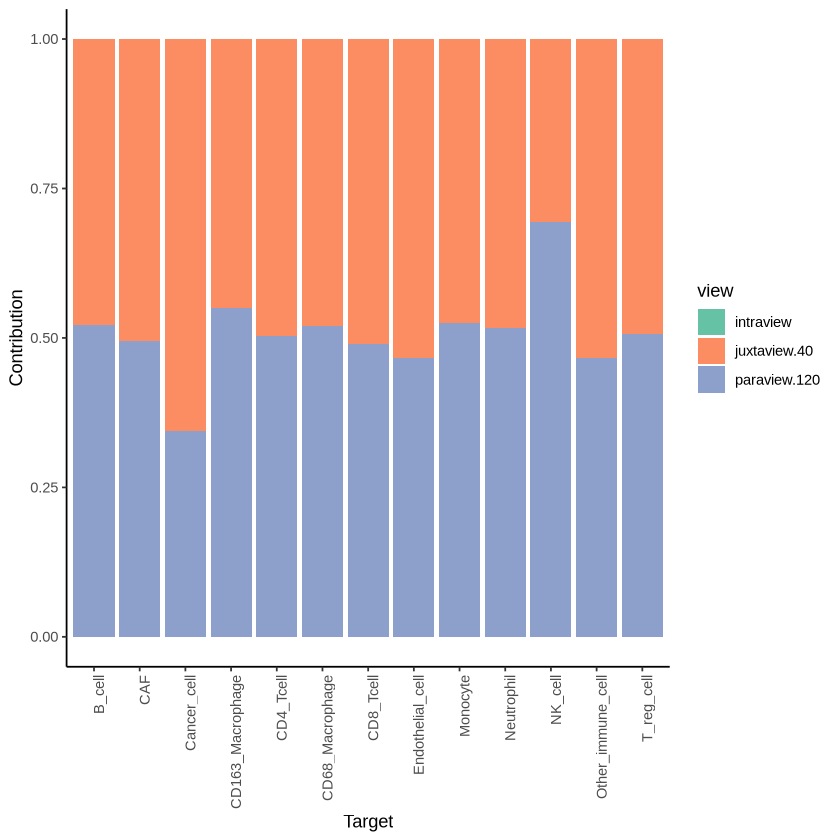

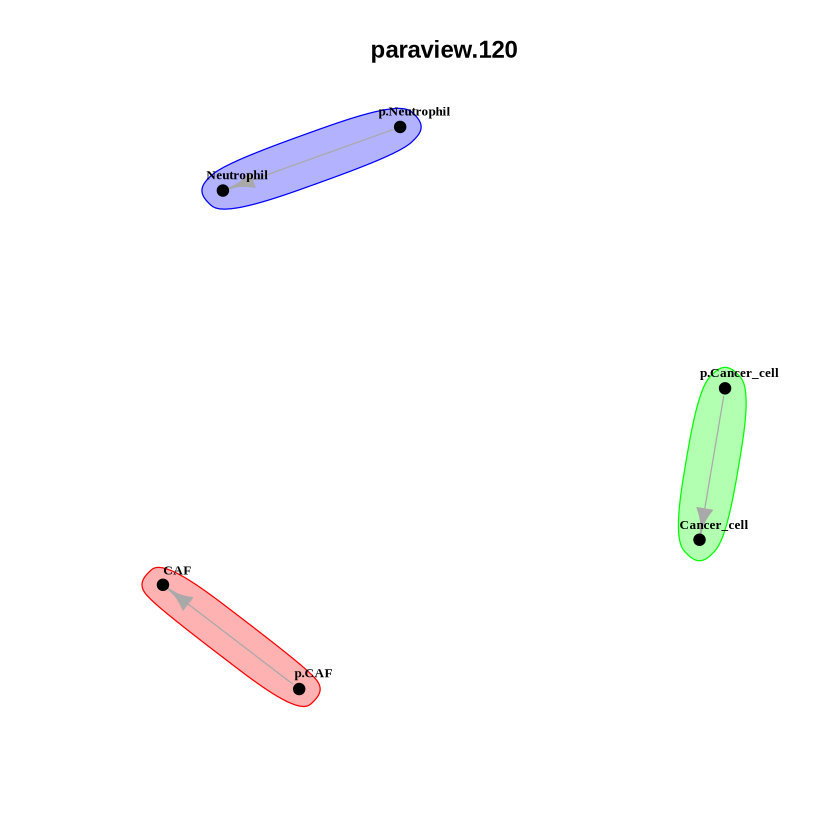

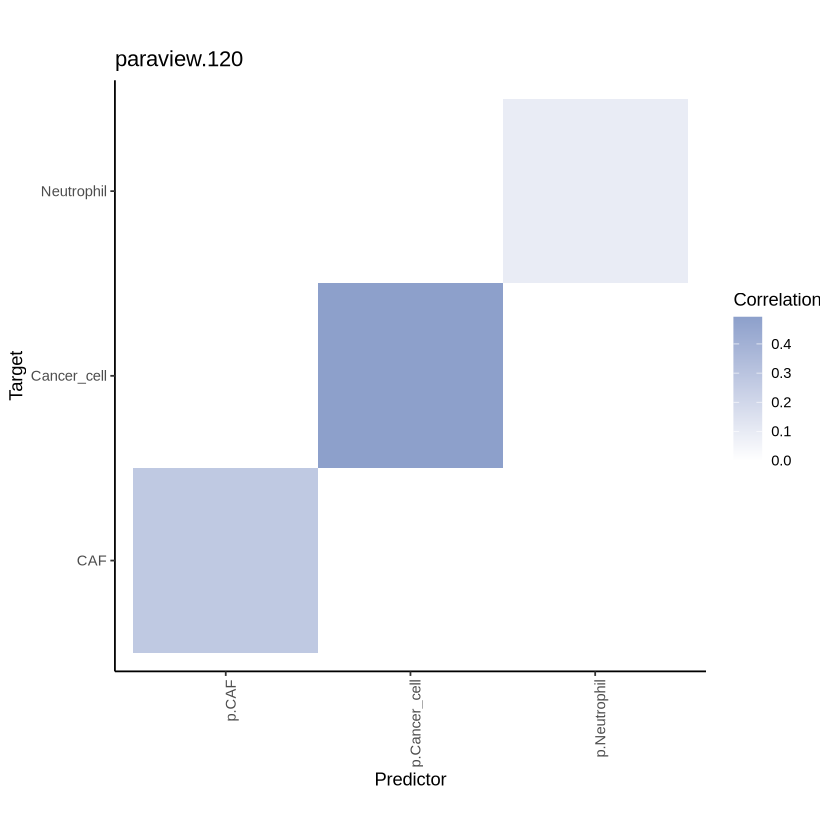

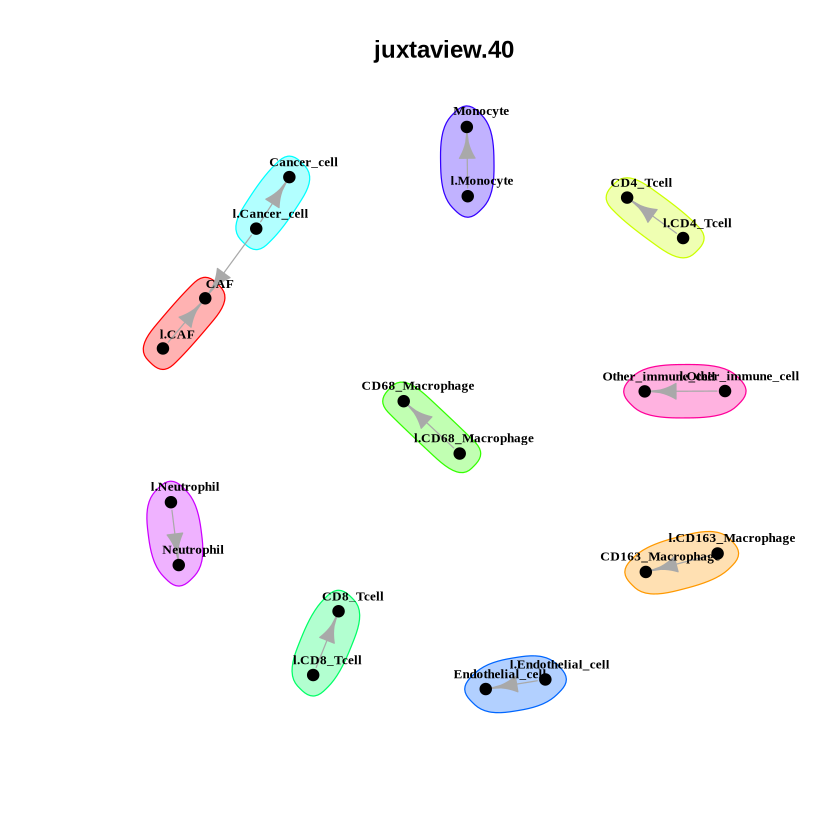

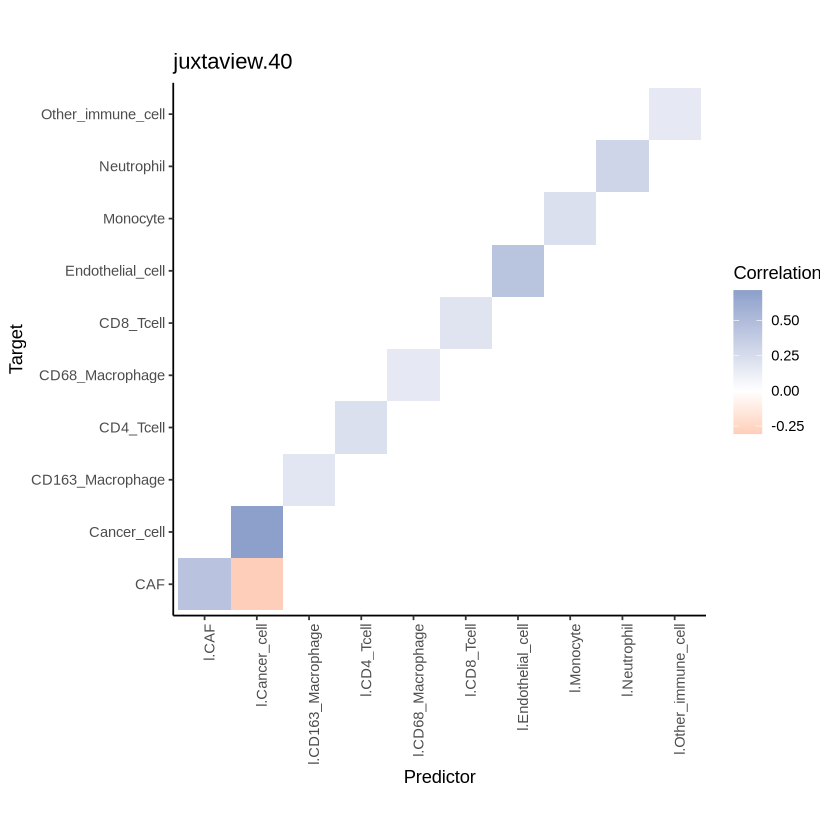

In [43]:
celltype_tc_results <- collect_results(celltype_outputfile, sample.pattern = "_TC_")
summarise_misty(celltype_tc_results, "misty_quadrant_celltype_TC")

#### Invasive margin (IM)








Aggregating



# A tibble: 13 × 2
   target            mean_value
   <chr>                  <dbl>
 1 Cancer_cell           69.1  
 2 Endothelial_cell      24.6  
 3 CAF                   21.2  
 4 Neutrophil            20.1  
 5 Monocyte               9.98 
 6 CD4_Tcell              8.33 
 7 CD163_Macrophage       7.25 
 8 CD68_Macrophage        6.40 
 9 CD8_Tcell              4.95 
10 Other_immune_cell      4.92 
11 B_cell                 4.32 
12 T_reg_cell             1.12 
13 NK_cell                0.699


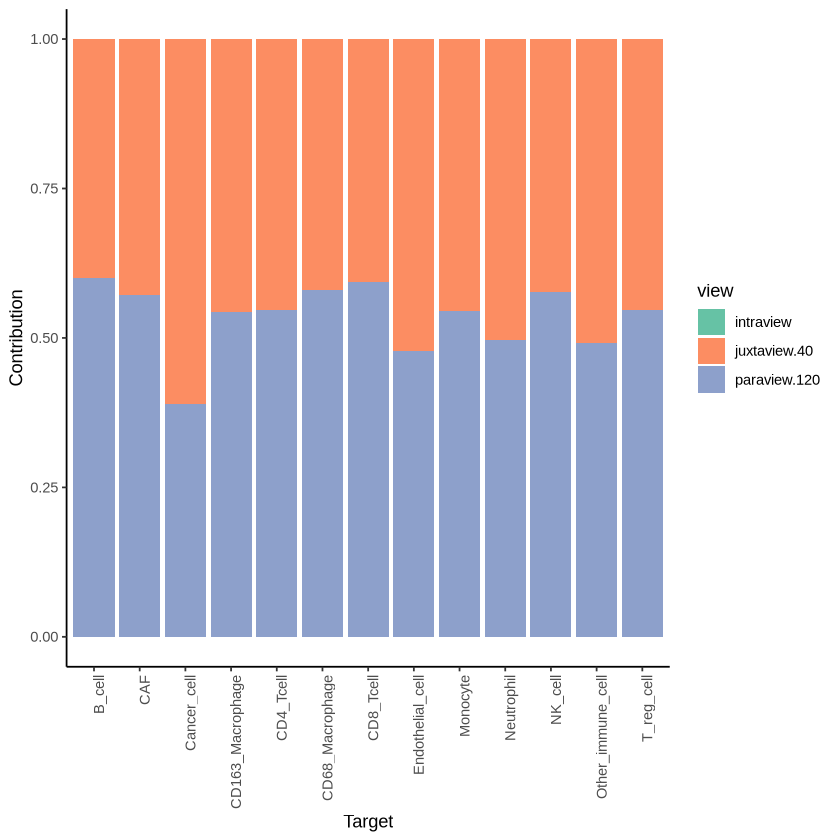

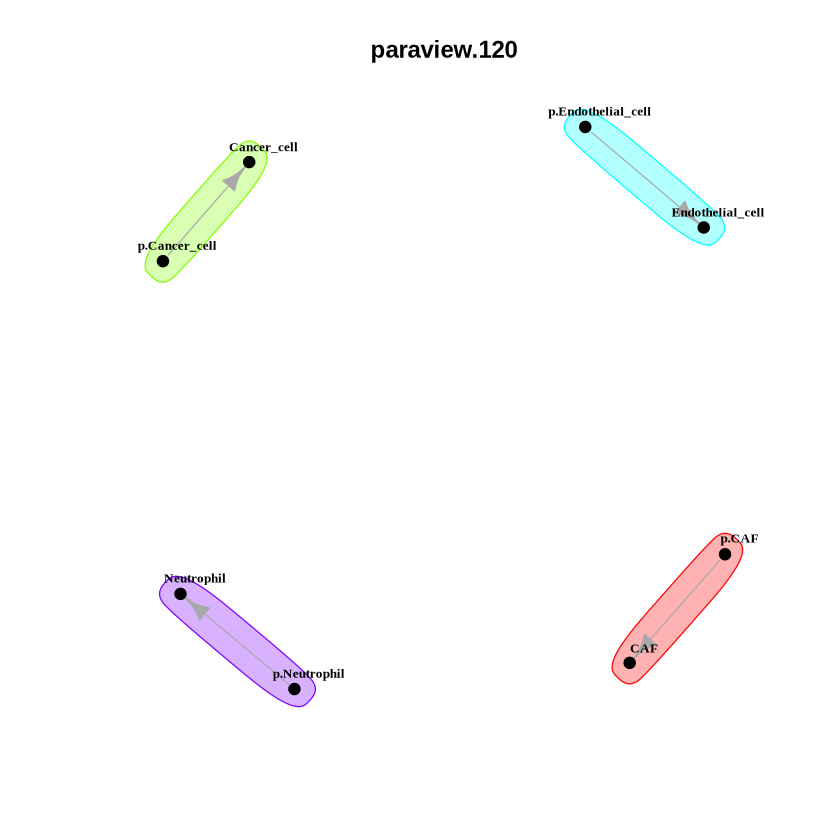

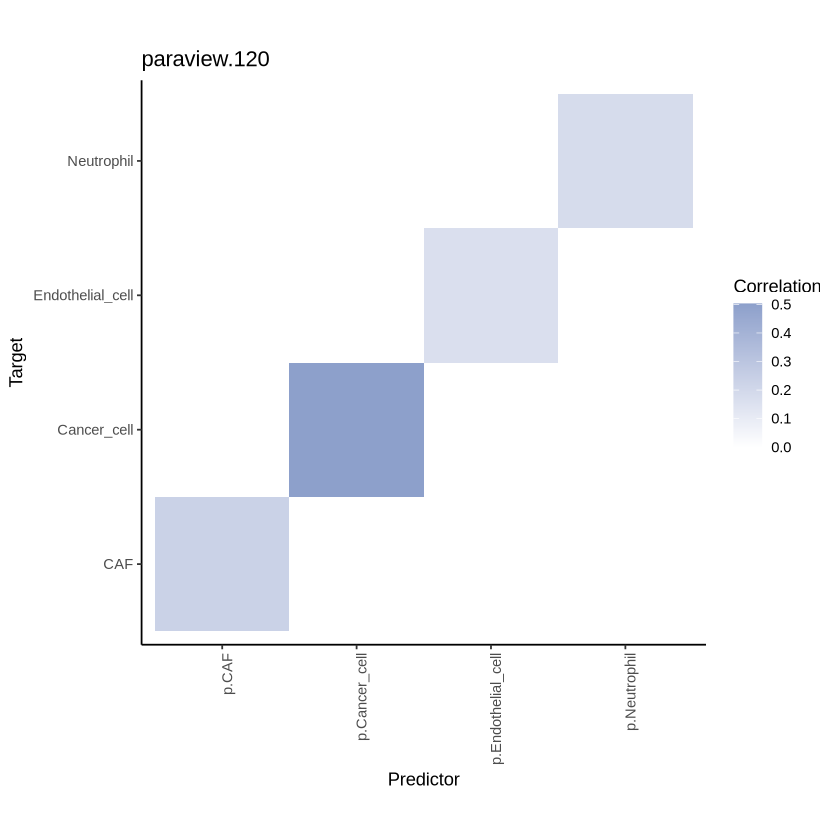

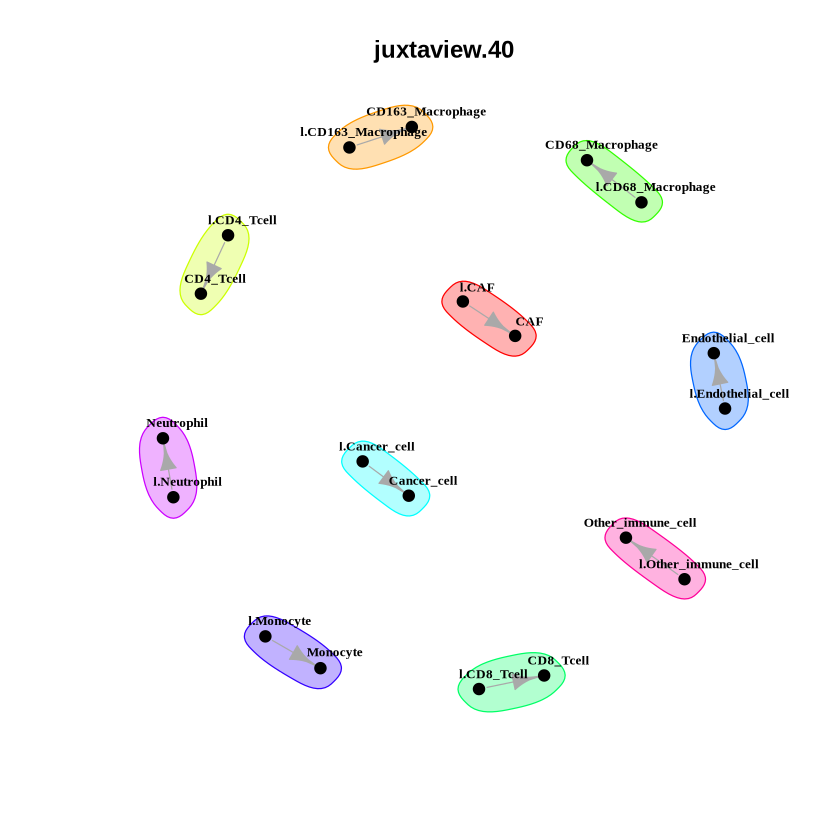

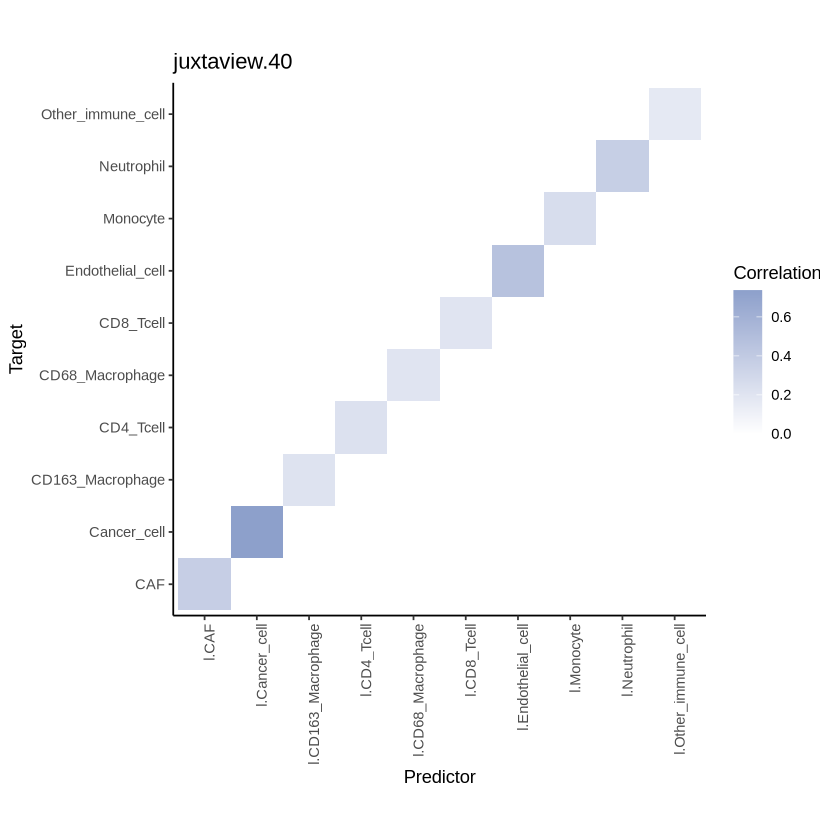

In [44]:
celltype_im_results <- collect_results(celltype_outputfile, sample.pattern = "_IM_")
summarise_misty(celltype_im_results, "misty_quadrant_celltype_IM")

## Export quadrant-level features

Finally, we export MISTy interaction scores per quadrant, as done for the original dataset to serve as features for classifiers (see *StageXGB.ipynb*).

In [45]:
export_features <- function(results, path) {
    quadrant_features <- extract_signature(results, type = "i", intersect.targets = FALSE, trim = 1)
    print(dim(quadrant_features))
    quadrant_features[is.na(quadrant_features)] <- floor(min(quadrant_features %>% select(-sample), na.rm = TRUE))
    quadrant_features <- quadrant_features %>% mutate(across(!sample, ~ ifelse(.x <= 0.9, 0, .x)))
    # Drop columns with all zeros
    keep <- names(which(quadrant_features %>% select(-sample, -contains("intra_")) %>% colSums() > 0))
    quadrant_features %>%
        select(sample, all_of(keep)) %>%
        write_csv(path)
}

In [46]:
export_features(lineage_results, "data/sampling/misty_quadrant_lineage_features.csv")
export_features(metab_results, "data/sampling/misty_quadrant_metab_features.csv")
export_features(celltype_results, "data/sampling/misty_quadrant_celltype_features.csv")

[1] 525 513
[1] 525 391
[1] 525 313
